In [89]:
#!pip install numpy==1.23.5 scikit-surprise
#import os; os.kill(os.getpid(), 9)  # Restart Colab kernel

# Table of Contents
1. [Introduction](#book-recommender-system)
2. [Project Workflow](#project-workflow)
3. [Data Loading & Preprocessing](#load-the-data)
4. [Section 1 - Exploratory Data Analysis EDA](#section-1---exploratory-data-analysis-eda)
5. [Building the Recommendation System](#building-the-recommendation-system)
6. [Model Training](#model-training)
    - [Content-Based Recommendation](#1-content-based-recommendation)
    - [SVD](#2-svd)
7. [Comparison of Methods](#comparison-of-methods)
8. [Key Findings](#key-findings)
9. [Limitations & Future Work](#limitations--future-work)

# A Comparative Study of Book Recommendation Algorithms

**Adaora Michelle Igwe**  
**Senior Seminar I**  
**Professor: Dr. Ning Zhang**

## Project Overview

This project compares content-based filtering and collaborative filtering using Singular Value Decomposition (SVD) for personalized book recommendations using the Book-Crossing dataset. The study focuses specifically on how the two approaches perform under different levels of user-rating sparsity.

## Research Question

**How do content-based filtering and collaborative filtering compare in top-N book recommendation performance under different levels of user-rating sparsity in the Book-Crossing dataset?**

## Project Workflow

1. **Data Loading and Preprocessing**
   - Load the Book-Crossing dataset.
   - Merge the books, ratings, and users data.
   - Clean missing and invalid values.

2. **Exploratory Data Analysis**
   - Examine the structure and distributions of the dataset.
   - Identify patterns and potential data-quality issues.

3. **Content-Based Filtering**
   - Represent book metadata using TF-IDF.
   - Calculate book similarity using cosine similarity.
   - Generate personalized top-5 recommendations.

4. **Collaborative Filtering**
   - Use user-book ratings to train an SVD collaborative-filtering model.
   - Generate rating predictions and recommendations.

5. **Evaluation and Comparison**
   - Evaluation and Comparison
   - Evaluate both models using Precision@5 and Recall@5 under controlled experimental conditions.
   - Compare performance under different levels of user-rating sparsity.
   - Repeat sparsity experiments across multiple random seeds to examine variability.

6. **Future Work**
   - Investigate how different book-popularity thresholds affect recommendation performance.
   - Further analyze the sparsity experiment and improve the content-based user-profile design.
   - Refine the comparative analysis and visualizations for the final report.

#### IMPORTS AND ENVIRONMENT SETUP

This section imports all the necessary libraries for the project.  
Each import is chosen for a specific purpose in the data science workflow:

- **pandas, numpy:** Data manipulation and numerical operations.
- **seaborn, matplotlib:** Data visualization for EDA and results.
- **sklearn.feature_extraction.text.TfidfVectorizer:** Converts book metadata into TF-IDF features for content-based filtering.
- **sklearn.metrics.pairwise (cosine_similarity, linear_kernel):** Computes similarity between books for recommendations.
- **sklearn.model_selection.train_test_split:** Splits data into training and testing sets.
- **pandas.plotting.scatter_matrix:** Visualizes pairwise relationships between numerical features.
- **sklearn.metrics.mean_squared_error:** Evaluates prediction accuracy (used for SVD RMSE).
- **scipy.sparse.csr_matrix:** Efficient storage for large, sparse matrices.
- **surprise (SVD, accuracy, Dataset, Reader):** Implements collaborative filtering (SVD) and evaluation.
- **surprise.model_selection.train_test_split:** Splits data for collaborative filtering.

> **Note:**  
> If you upgrade numpy or install new packages, restart the kernel before running the rest of the notebook.

In [90]:

# After running this cell, restart the kernel (Runtime > Restart kernel) to ensure the upgraded numpy is used.
# Then, re-run all cells below.

import pandas as pd
import numpy as np

import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.metrics.pairwise import linear_kernel

from pandas.plotting import scatter_matrix

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_squared_error
from scipy.sparse import csr_matrix

from surprise import SVD, accuracy, Dataset, Reader

import seaborn as sns
import matplotlib.pyplot as plt

from surprise.model_selection import train_test_split as suprise_split
print("Imports worked!")

Imports worked!


#### Load the Data

In this section, I load the three main files from the Book-Crossing dataset:

- **books.csv:** Contains book metadata such as ISBN, title, author, publisher, year of publication, and image URLs.
- **ratings.csv:** Contains user ratings for books, including user IDs, ISBNs, and the rating (0–10).
- **users.csv:** Contains user demographic information such as user ID, location, and age.

**Dataset Overview:**  
The Book-Crossing dataset is a widely used benchmark for recommender systems. It consists of three tables:
- **Books:** Metadata for each book (title, author, publisher, etc.).
- **Ratings:** Explicit ratings (0–10) that users have given to books. A rating of 0 typically means the user has not rated the book.
- **Users:** Demographic information about users (location, age).

These files are merged and preprocessed in the following steps to create a unified dataset for analysis and model building.


In [91]:
books_df = pd.read_csv('../data/books.csv', sep=";",on_bad_lines="skip",encoding='latin-1')
ratings_df = pd.read_csv('../data/ratings.csv',sep=";",on_bad_lines="skip",encoding='latin-1')
users_df = pd.read_csv('../data/users.csv', sep=";",on_bad_lines="skip",encoding='latin-1')

C:\Users\adaor\AppData\Local\Temp\ipykernel_37448\2375675941.py:1: DtypeWarning: Columns (0: Year-Of-Publication) have mixed types. Specify dtype option on import or set low_memory=False.
  books_df = pd.read_csv('../data/books.csv', sep=";",on_bad_lines="skip",encoding='latin-1')


In [92]:
print("Number of unique users:", users_df['User-ID'].nunique())
print("Number of unique books:", books_df['ISBN'].nunique())
print("Total number of ratings:", len(ratings_df))

Number of unique users: 278858
Number of unique books: 271360
Total number of ratings: 1149780


#### Data Preprocessing

In this section, I prepare the raw data for analysis and modeling. The main steps include:

- **Merging Data:** I combine the books, ratings, and users tables into a single DataFrame using common keys (ISBN and User-ID). This unified dataset allows us to analyze relationships betIen users, books, and ratings.
- **Handling Missing Values:** I address missing or invalid entries in key columns (such as publication year, author, publisher, and user age) to ensure data quality. For example, I fill missing authors/publishers with "Unknown" and impute invalid ages with the median.
- **Cleaning and Transforming Columns:** I correct data types, remove outliers (e.g., unrealistic ages or publication years), and drop unnecessary columns (such as image URLs and highly-missing location data).
- **Removing Duplicates:** I ensure each user can only rate a book once by dropping duplicate (User-ID, ISBN) pairs.
- **Feature Engineering:** I create new features, such as binarized ratings or implicit feedback, to support different recommendation approaches.

**Why these steps?**  
Data preprocessing is essential to:
- Improve data quality and consistency.
- Reduce noise and bias from invalid or missing values.
- Ensure that the recommendation algorithms receive clean, well-structured input for accurate and meaningful results.

In [93]:
books_df.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


In [94]:
users_df.head()

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.00
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.00
4,5,"farnborough, hants, united kingdom",NaN


In [95]:
ratings_df.head()

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [96]:
df = books_df.merge(ratings_df, on='ISBN').merge(users_df, on='User-ID')
df.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,User-ID,Book-Rating,Location,Age
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,2,0,"stockton, california, usa",18.00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,8,5,"timmins, ontario, canada",NaN
2,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,11400,0,"ottawa, ontario, canada",49.00
3,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,11676,8,"n/a, n/a, n/a",NaN
4,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,41385,0,"sudbury, ontario, canada",NaN


#### Section 1 - Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is a crucial step in any data science project. It helps us understand the structure, patterns, and anomalies in the dataset before applying any machine learning or statistical models.

##### Why EDA is Important

- **Data Quality Assessment:** EDA helps identify missing values, outliers, and inconsistencies in the data.
- **Understanding Distributions:** By visualizing distributions of features (e.g., ratings, publication years, user ages), I can detect skewness, biases, or unusual patterns.
- **Feature Relationships:** EDA reveals relationships and correlations between variables, which can inform feature engineering and model selection.
- **Guiding Preprocessing:** Insights from EDA guide decisions on data cleaning, transformation, and handling of categorical/numerical variables.
- **Detecting Data Leakage:** Early detection of data leakage or data that should not be used for training improves model reliability.

##### What I Did in EDA

1. **Data Type Inspection:**  
   - Checked data types of all columns to ensure correct formats for analysis and modeling.
2. **Year of Publication Cleaning:**  
   - Identified and handled invalid publication years (e.g., text entries, out-of-range years).
   - Replaced invalid or missing years with the median year.
3. **Distribution Visualization:**  
   - Plotted histograms for key numerical features (e.g., user IDs, book ratings, ages).
   - Observed that most ratings are 0 (unrated), and non-zero ratings are biased towards higher values.
4. **Feature Engineering:**  
   - Created an `implicit_feedback` column to binarize ratings (1 if rating > 4, else 0).
5. **Outlier Handling:**  
   - Detected unrealistic ages (e.g., 0 or >100) and imputed them with the median age.
6. **Categorical Feature Analysis:**  
   - Counted unique values in categorical columns (authors, titles, publishers) to assess their suitability for modeling.
7. **Location Parsing:**  
   - Split the location field into city, state, and country for more granular analysis.
8. **Dropping Irrelevant Columns:**  
   - Removed image URL columns and highly-missing location data to reduce noise.
9. **Duplicate Removal:**  
   - Ensured each user-book pair is unique by dropping duplicate ratings.
10. **Missing Value Handling:**  
    - Imputed missing authors and publishers with "Unknown".
    - Imputed missing ages with the median.
    - Dropped location columns due to excessive missingness.
11. **Final Data Quality Check:**  
    - Visualized missing values per column using a bar plot.

##### Advantages of EDA

- **Improves Model Performance:** Clean, well-understood data leads to better model accuracy and generalization.
- **Reduces Errors:** Early detection of data issues prevents downstream problems in modeling and evaluation.
- **Informs Feature Engineering:** EDA highlights which features are most informative or require transformation.
- **Supports Transparent Reporting:** Visualizations and summary statistics make the data science process more interpretable and reproducible.

##### Example EDA Visualization

Below is an example histogram generated during EDA, showing the distribution of key numerical features:
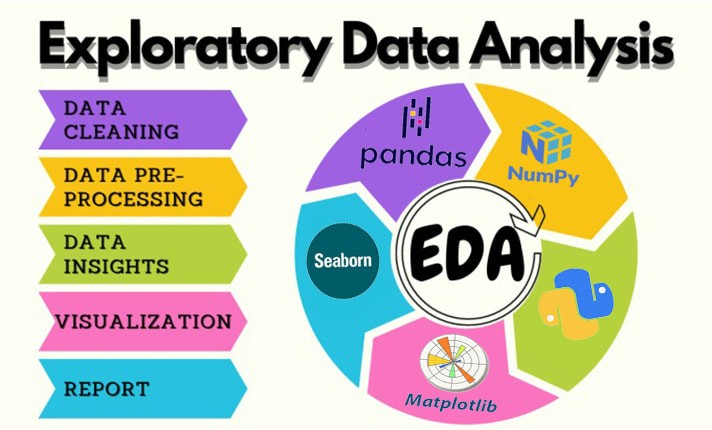

By performing thorough EDA, I ensure that our recommender system is built on a solid foundation of clean, well-understood data.

#### Numerical Features

In this section, I focus on analyzing and cleaning the **numerical features** in our dataset, which are critical for building robust recommendation models.

##### What I Are Doing

- **Inspecting Data Types:**  
  I check the data types of all columns to ensure numerical features are correctly formatted for analysis and modeling.

- **Year of Publication Cleaning:**  
  - Convert the 'Year-Of-Publication' column to numeric, coercing invalid strings to NaN.
  - Identify and handle invalid years (e.g., years less than 1450 or greater than 2025, or non-numeric entries).
  - Replace missing or invalid years with the median year from valid entries.

- **Analyzing Distributions:**  
  - Plot histograms for key numerical features such as user IDs, book ratings, and ages.
  - This helps us understand the spread, skewness, and presence of outliers in the data.

- **Handling Outliers:**  
  - Detect unrealistic values in the 'Age' column (e.g., ages below 5 or above 100).
  - Impute these outliers with the median age to maintain data integrity.

- **Feature Engineering:**  
  - Create new features such as `implicit_feedback` to binarize ratings (e.g., 1 if rating > 4, else 0).
  - This supports both explicit and implicit feedback modeling.

##### Why These Steps Are Important

- **Data Quality:**  
  Cleaning and validating numerical features ensures that the models are trained on accurate and meaningful data.

- **Reducing Bias and Noise:**  
  Handling outliers and invalid entries prevents skewed results and improves model performance.

- **Better Insights:**  
  Visualizing distributions and summary statistics helps in understanding user behavior and rating patterns.

- **Supporting Model Requirements:**  
  Many machine learning algorithms require clean, numeric input. Proper preprocessing is essential for successful training and evaluation.

---

By carefully preparing numerical features, I lay the groundwork for effective exploratory analysis and reliable recommendation models.

In [97]:
print(df.dtypes)
print(df['Year-Of-Publication'].unique())

ISBN                       str
Book-Title                 str
Book-Author                str
Year-Of-Publication     object
Publisher                  str
Image-URL-S                str
Image-URL-M                str
Image-URL-L                str
User-ID                  int64
Book-Rating              int64
Location                   str
Age                    float64
dtype: object
[2002 2001 1991 1999 2000 1993 1996 1988 2004 1998 1994 2003 1997 1983
 1979 1995 1982 1985 1992 1986 1978 1980 1952 1987 1990 1981 1989 1984 0
 1968 1961 1958 1974 1976 1971 1977 1975 1965 1941 1970 1962 1973 1972
 1960 1966 1920 1956 1959 1953 1951 1942 1963 1964 1969 1954 1950 1967
 2005 1957 1940 1937 1955 1946 1936 1930 2011 1925 1948 1943 1947 1945
 1923 2020 1939 1926 1938 2030 1911 1904 1949 1932 1928 1929 1927 1931
 1914 2050 1934 1910 1933 1902 1924 1921 1900 2038 2026 1944 1917 1901
 2010 1908 1906 1935 1806 2021 '2000' '1995' '1999' '2004' '2003' '1990'
 '1994' '1986' '1989' '2002' '1981' '1993'

It reveals that the Year-Of-Publication column includes:
- Valid numeric years (e.g., 2001, 1984)
- Text entries (e.g., 'Gallimard', 'DK Publishing Inc')
- Zeros and out-of-range years (e.g., '0', '2050', '2038', '1806', '1378')
- Quoted strings mixed with unquoted numbers (some entries are strings)

In [98]:
# Step 1: Convert to numeric, invalid strings become NaN
df['Year-Of-Publication'] = pd.to_numeric(df['Year-Of-Publication'], errors='coerce')

# Step 2: Set invalid numeric values (e.g., 0, <1450, >2025) to NaN
df.loc[(df['Year-Of-Publication'] < 1450) | (df['Year-Of-Publication'] > 2025), 'Year-Of-Publication'] = None

# Step 3: Calculate median from valid entries
median_year = int(df['Year-Of-Publication'].median())

# Step 4: Fill missing (invalid or coerced) values with the median
df['Year-Of-Publication'] = df['Year-Of-Publication'].fillna(median_year).astype(int)

print(df['Year-Of-Publication'].unique())


[2002 2001 1991 1999 2000 1993 1996 1988 2004 1998 1994 2003 1997 1983
 1979 1995 1982 1985 1992 1986 1978 1980 1952 1987 1990 1981 1989 1984
 1968 1961 1958 1974 1976 1971 1977 1975 1965 1941 1970 1962 1973 1972
 1960 1966 1920 1956 1959 1953 1951 1942 1963 1964 1969 1954 1950 1967
 2005 1957 1940 1937 1955 1946 1936 1930 2011 1925 1948 1943 1947 1945
 1923 2020 1939 1926 1938 1911 1904 1949 1932 1928 1929 1927 1931 1914
 1934 1910 1933 1902 1924 1921 1900 1944 1917 1901 2010 1908 1906 1935
 1806 2021 2012 2006 1909 2008 1919 1922 1897 2024]


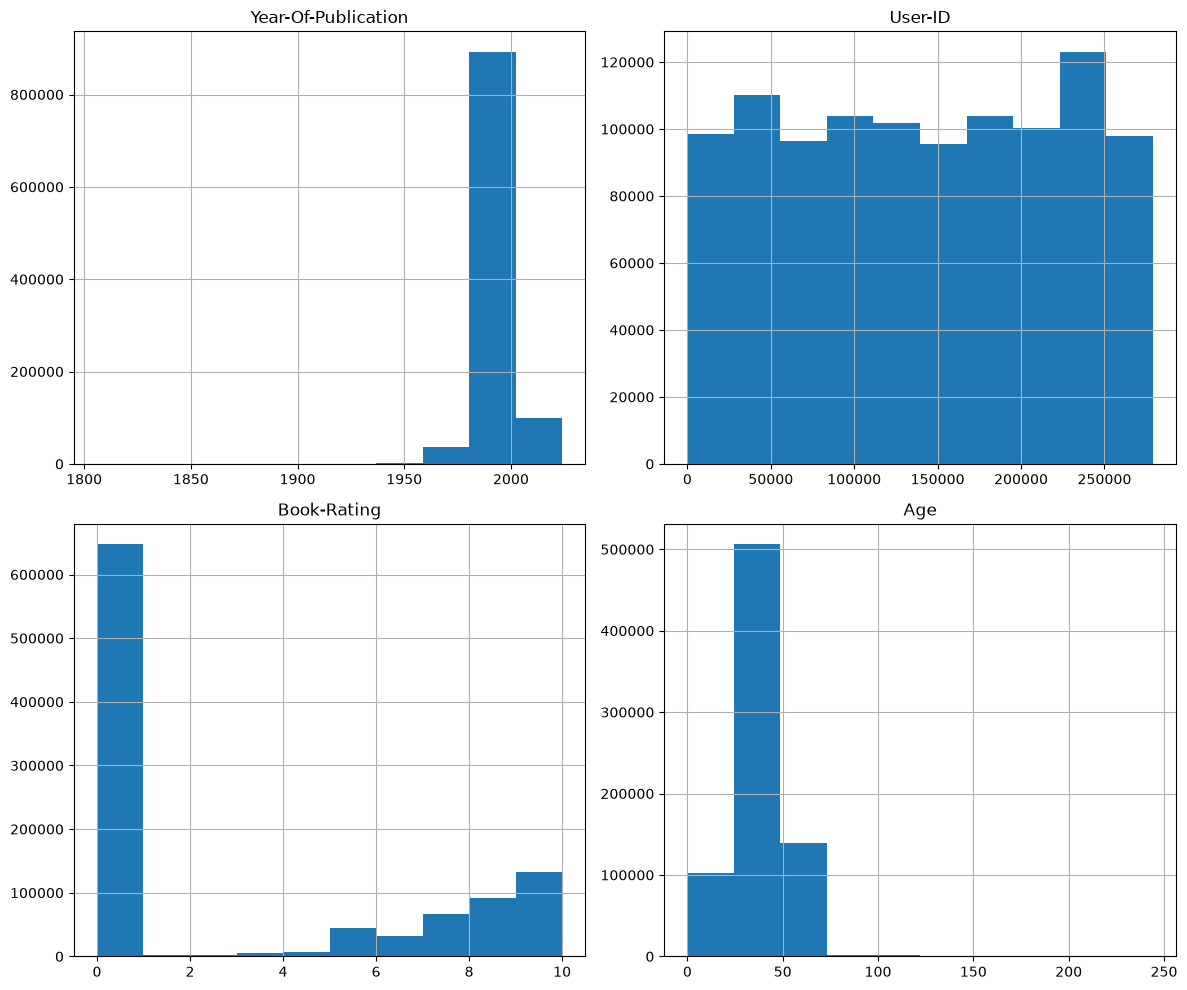

In [99]:
df.hist(bins=10, figsize=(12, 10))
plt.tight_layout()
plt.show()

#### Observations of Histogram:
- User-ID Distribution:
  - The distribution looks uniformly dense across user IDs.
  - This suggests many unique users rated books — there's no heavy skew toward a small group of users.
- Book-Rating Distribution:
  - Most ratings are 0, which likely means 'Users added books to their list but didn’t rate them.'
  - A clear positive bias: most non-zero ratings are 7–10.
  - I add a column called 'binarized-rating' to keep 0s but I decode them not to lose many data. If the rating is greater than 0, I assign 1 to it. else, I keep it 0.


In [100]:
df['implicit_feedback'] = df['Book-Rating'].apply(lambda x: 1 if x > 4 else 0)
df['implicit_feedback'].value_counts()

implicit_feedback
0    663885
1    367251
Name: count, dtype: int64

In [101]:
pd.set_option('display.float_format', '{:.2f}'.format)
df.describe(include='all')

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,User-ID,Book-Rating,Location,Age,implicit_feedback
count,1031136,1031136,1031134,1031136.00,1031134,1031136,1031136,1031132,1031136.00,1031136.00,1031136,753301.00,1031136.00
unique,270151,241071,101587,NaN,16729,269842,269842,269839,NaN,NaN,22480,NaN,NaN
top,0971880107,Wild Animus,Stephen King,NaN,Ballantine Books,http://images.amazon.com/images/P/0971880107.0...,http://images.amazon.com/images/P/0971880107.0...,http://images.amazon.com/images/P/0971880107.0...,NaN,NaN,"toronto, ontario, canada",NaN,NaN
freq,2502,2502,10053,NaN,34724,2502,2502,2502,NaN,NaN,14782,NaN,NaN
mean,NaN,NaN,NaN,1995.33,NaN,NaN,NaN,NaN,140594.50,2.84,NaN,37.40,0.36
std,NaN,NaN,NaN,7.26,NaN,NaN,NaN,NaN,80524.66,3.85,NaN,14.10,0.48
min,NaN,NaN,NaN,1806.00,NaN,NaN,NaN,NaN,2.00,0.00,NaN,0.00,0.00
25%,NaN,NaN,NaN,1992.00,NaN,NaN,NaN,NaN,70415.00,0.00,NaN,28.00,0.00
50%,NaN,NaN,NaN,1997.00,NaN,NaN,NaN,NaN,141210.00,0.00,NaN,35.00,0.00
75%,NaN,NaN,NaN,2001.00,NaN,NaN,NaN,NaN,211426.00,7.00,NaN,45.00,1.00


The maximum value for age range is 244 and minimum age is 0. These values dont make sense because a new born baby cant rate a book, and usually the maximum age for humans are 100 years. So these extreme values seem to be outliers and I try to filter the unrealistic values. I impute the outliers with median:

In [102]:
median_age = df[(df['Age'] >= 5) & (df['Age'] <= 100)]['Age'].median()
df['Age'] = df['Age'].apply(lambda x: median_age if x < 5 or x > 100 else x)


#### Categorical Features

In this section, I analyze the categorical features in the dataset, such as book authors, book titles, and publishers.

##### What I Are Doing

- **Counting Unique Values:**  
  I count the number of unique values in columns like 'Book-Author', 'Book-Title', and 'Publisher' to understand their diversity and potential usefulness for modeling.
- **Assessing Suitability:**  
  I determine whether these columns can be treated as categorical variables or if they are too high-cardinality for standard categorical encoding.
- **Location Parsing:**  
  I further analyze the 'Location' column by splitting it into 'City', 'State', and 'Country' for more granular analysis.

##### Why These Steps Are Important

- **Feature Engineering:**  
  Understanding the uniqueness and distribution of categorical features helps decide how to encode or use them in recommendation algorithms.
- **Reducing Dimensionality:**  
  High-cardinality features may need special handling to avoid overfitting or excessive memory usage.
- **Improving Model Interpretability:**  
  Clean and well-understood categorical features can improve the interpretability and performance of content-based recommenders.

---

**Output Explanation:**  
The code below prints the number of distinct values in 'Book-Author', 'Book-Title', and 'Publisher'.  
This output helps us see that these columns have a very large number of unique values, so they are not suitable for traditional categorical encoding. Instead, they are better used as text features for content-based filtering.

In [103]:
print("Number of Distinct Values in Authoers; ", df['Book-Author'].nunique())
print("Number of Distinct Values in Book Titles; ", df['Book-Title'].nunique())
print("Number of Distinct Values in Publisher; ", df['Publisher'].nunique())


Number of Distinct Values in Authoers;  101587
Number of Distinct Values in Book Titles;  241071
Number of Distinct Values in Publisher;  16729


Since I have two many unique values for each of the columns above, they are not considered categorical.

In [104]:
df['Location'].value_counts()

Location
toronto, ontario, canada         14782
n/a, n/a, n/a                    11162
chicago, illinois, usa            8499
seattle, washington, usa          8392
ottawa, ontario, canada           8116
                                 ...  
holley, new york, usa                1
schwaz, tirol, austria               1
n***, sachsen-anahlt, germany        1
culiacán, sinaloa, mexico            1
linclon, nebraska, usa               1
Name: count, Length: 22480, dtype: int64

### Location Preprocessing

The location field contains city, state, and country information in a single string. After merging the datasets, I split the location information directly from the merged dataframe to preserve the correct association between each user and their location.

In [105]:

df[['City','State','Country']] = df['Location'].str.strip().str.split(",", expand=True, n=2)
for col in ['City','State','Country']:
    df[col] = df[col].where(df[col].isnull(), df[col].astype(str).str.strip())

df.drop('Location', axis=1, inplace=True, errors='ignore')

I also drop the image url columns ('Image-URL-S', 'Image-URL-M', 'Image-URL-L') because they dont provide any useful information.

In [106]:
df.drop(['Image-URL-S', 'Image-URL-M', 'Image-URL-L'], axis=1, inplace=True, errors='ignore')


In [107]:
df.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,User-ID,Book-Rating,Age,implicit_feedback,City,State,Country
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,2,0,18.00,0,stockton,california,usa
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,8,5,NaN,1,timmins,ontario,canada
2,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,11400,0,49.00,0,ottawa,ontario,canada
3,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,11676,8,NaN,1,n/a,n/a,n/a
4,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,41385,0,NaN,0,sudbury,ontario,canada


In [108]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1031136 entries, 0 to 1031135
Data columns (total 12 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   ISBN                 1031136 non-null  str    
 1   Book-Title           1031136 non-null  str    
 2   Book-Author          1031134 non-null  str    
 3   Year-Of-Publication  1031136 non-null  int64  
 4   Publisher            1031134 non-null  str    
 5   User-ID              1031136 non-null  int64  
 6   Book-Rating          1031136 non-null  int64  
 7   Age                  753301 non-null   float64
 8   implicit_feedback    1031136 non-null  int64  
 9   City                 1031136 non-null  str    
 10  State                1031136 non-null  str    
 11  Country              1031136 non-null  str    
dtypes: float64(1), int64(4), str(7)
memory usage: 94.4 MB


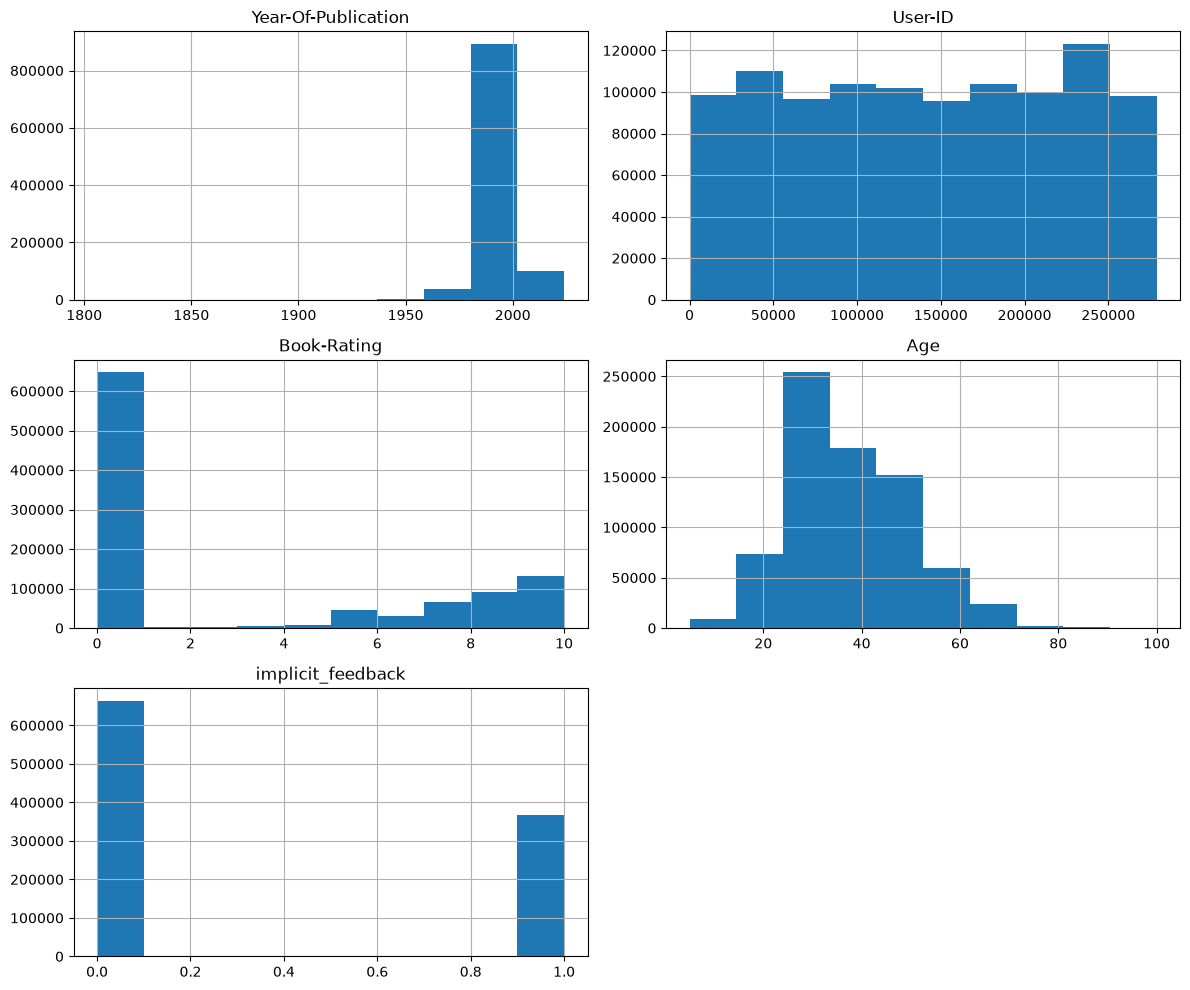

In [109]:
df.hist(bins=10, figsize=(12, 10))
plt.tight_layout()
plt.show()

I need to drop the duplicated user giving vote for the same book. meaning that a user can have only on rating per book:

In [110]:
print("Number of data before removing duplicates: ", df.shape)
df_clean = df.drop_duplicates(['User-ID','ISBN'],keep='first')
print("Number of data after removing duplicates: ", df_clean.shape)

Number of data before removing duplicates:  (1031136, 12)
Number of data after removing duplicates:  (1031136, 12)


In [111]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1031136 entries, 0 to 1031135
Data columns (total 12 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   ISBN                 1031136 non-null  str    
 1   Book-Title           1031136 non-null  str    
 2   Book-Author          1031134 non-null  str    
 3   Year-Of-Publication  1031136 non-null  int64  
 4   Publisher            1031134 non-null  str    
 5   User-ID              1031136 non-null  int64  
 6   Book-Rating          1031136 non-null  int64  
 7   Age                  753301 non-null   float64
 8   implicit_feedback    1031136 non-null  int64  
 9   City                 1031136 non-null  str    
 10  State                1031136 non-null  str    
 11  Country              1031136 non-null  str    
dtypes: float64(1), int64(4), str(7)
memory usage: 94.4 MB


#### Handling Missing Values
I took a different approach to handle the missing value for each column.
- For 'Book-Author' and 'Publisher', I filled them with 'Unknown'
- For age, I impute them with median, because in case of dropping them, I would lose 25% of the data which is huge.
- For location, since I were missing 75% of the data, I decided to drop that.

In [112]:
# Impute missing value of Author and Publisher
df_clean['Book-Author'] = df_clean['Book-Author'].fillna('Unknown')
df_clean['Publisher'] = df_clean['Publisher'].fillna('Unknown')

#Impute Missing values for Age with median
median_age = df_clean['Age'].median()
df_clean['Age'] = df_clean['Age'].fillna(median_age)

# Dropping Location related columns
df_clean.drop(['City', 'State', 'Country'], axis=1, inplace=True)



In [113]:
print(df_clean.isnull().sum())

ISBN                   0
Book-Title             0
Book-Author            0
Year-Of-Publication    0
Publisher              0
User-ID                0
Book-Rating            0
Age                    0
implicit_feedback      0
dtype: int64


### Handling Missing Values

I checked the merged dataset for missing values before building the recommendation models. Missing author and publisher values are replaced with `"Unknown"`, while missing user ages are replaced with the median age. Location columns are removed because they are not currently used by either recommendation approach.

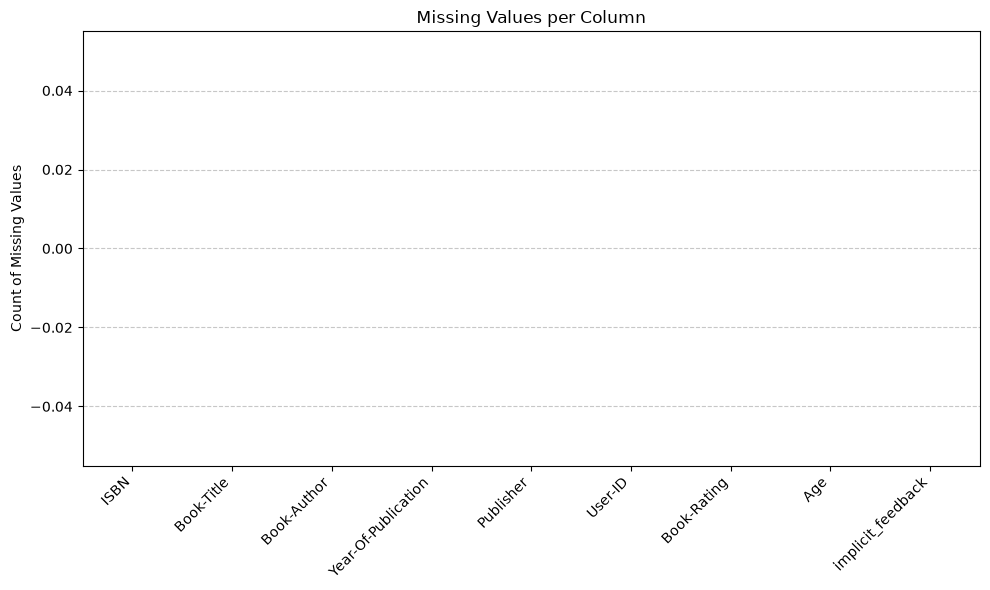

In [114]:
# Calculate number of missing values per column
missing_counts = df_clean.isnull().sum()

# Plot
plt.figure(figsize=(10, 6))
missing_counts.plot(kind='bar', color='tomato')
plt.title('Missing Values per Column')
plt.ylabel('Count of Missing Values')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


In [115]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1031136 entries, 0 to 1031135
Data columns (total 9 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   ISBN                 1031136 non-null  str    
 1   Book-Title           1031136 non-null  str    
 2   Book-Author          1031136 non-null  str    
 3   Year-Of-Publication  1031136 non-null  int64  
 4   Publisher            1031136 non-null  str    
 5   User-ID              1031136 non-null  int64  
 6   Book-Rating          1031136 non-null  int64  
 7   Age                  1031136 non-null  float64
 8   implicit_feedback    1031136 non-null  int64  
dtypes: float64(1), int64(4), str(4)
memory usage: 70.8 MB


#### Building the Recommendation System

With the cleaned data, I build and evaluate two main types of recommendation systems:

- **Content-Based Recommendation:** Uses book metadata (title, author, publisher) and TF-IDF with cosine similarity.
- **Collaborative Filtering (SVD):** Model-based approach using matrix factorization (Surprise SVD) on user-book ratings.

#### Model Training

#### 1. Content-Based Recommendation

In this section, I implement a **content-based recommender system** that suggests books to users based on the similarity of book metadata (such as title, author, and publisher).

##### What I Am Doing

- **Filtering Popular Books:**  
  To reduce memory usage and focus on relevant items, I filter the dataset to include only books with a minimum number of ratings (popularity threshold).
- **Splitting Data:**  
  I split the filtered data into training and test sets to evaluate recommendation performance.
- **Metadata Combination:**  
  For each book, I combine the title, author, and publisher into a single text field called `metadata`.
- **TF-IDF Vectorization:**  
  I use the TF-IDF (Term Frequency-Inverse Document Frequency) technique to convert the combined metadata into numerical feature vectors, capturing the importance of words across all books.
- **Cosine Similarity Calculation:**  
  I compute the cosine similarity between all pairs of books based on their TF-IDF vectors. This measures how similar two books are in terms of their metadata.
- **Recommendation Function:**  
  For a given user, I recommend books that are most similar to the highest-rated book they have read, excluding books they have already rated.
- **Initial Evaluation (Hit Rate@5):**
  As an initial evaluation, I check whether at least one of the top-5 recommended books for each user appears in that user's held-out test interactions. This measures Hit Rate@5 rather than true Precision@5. Precision@5 and Recall@5 will be implemented as part of the final evaluation.

##### Why These Steps Are Important

- **Personalization:**  
  Content-based filtering provides personalized recommendations based on a user's past preferences and the content of items.
- **Interpretability:**  
  Recommendations can be explained by showing which features (e.g., author, title) contributed to the similarity.
- **No Need for User Overlap:**  
  Unlike collaborative filtering, content-based methods do not require users to have overlapping ratings.


In [ ]:
# --- TUNING PARAMETERS ---
# What to Observe
# Lower popularity threshold → more books, slower, possibly higher hit rate.
# Higher max_features → more text features, slower, sometimes better recommendations.
# Larger user_test → more robust evaluation, slower.
POPULARITY_THRESHOLD = 300    # Try 10, 50, 100, 200, etc.
TFIDF_MAX_FEATURES = 3000     # Try 500, 1000, 2000, etc.


# Step 1: Filter popular books to reduce memory usage
popular_books = df_clean['ISBN'].value_counts()[lambda x: x > POPULARITY_THRESHOLD].index
df_small = df_clean[df_clean['ISBN'].isin(popular_books)].copy()

# Step 2: Split by (user, book) pairs, not by user
train_df, test_df = train_test_split(df_small, test_size=0.2, random_state=42)

user_test = test_df['User-ID'].unique() # Use all users in test set for evaluation

# Step 3: Remove duplicate books from train set to avoid redundancy
df_books = train_df.drop_duplicates(subset='ISBN').copy()
df_books = df_books.reset_index(drop=True)

# Step 4: Combine metadata and preprocess
df_books['metadata'] = (
    df_books['Book-Title'].astype(str) + ' ' +
    df_books['Book-Author'].astype(str) + ' ' +
    df_books['Publisher'].astype(str)
)

print("Books in df_books:", len(df_books))
print("Users in user_test:", len(user_test))

# Step 5: Create TF-IDF matrix
tfidf = TfidfVectorizer(stop_words='english', max_features=TFIDF_MAX_FEATURES)
tfidf_matrix = tfidf.fit_transform(df_books['metadata'])

# Step 6: Compute cosine similarity between books
cos_sim = cosine_similarity(tfidf_matrix)

# Print details about the cosine similarity matrix
print("Cosine Similarity Matrix shape:", cos_sim.shape)

# Show a small sample of the matrix for readability
print("\nSample of Cosine Similarity Matrix (first 5x5 block):")
print(pd.DataFrame(cos_sim).iloc[:5, :5])

# Show summary statistics
print("\nCosine Similarity Matrix Statistics:")
print(f"Min: {cos_sim.min():.4f}")
print(f"Max: {cos_sim.max():.4f}")
print(f"Mean: {cos_sim.mean():.4f}")
print(f"Std: {cos_sim.std():.4f}")

# Step 7: Create book index mapping (ISBN to positional index)
book_indices = pd.Series(df_books.index, index=df_books['ISBN'])

# Step 8: Recommendation function
def recommend_for_user(user_id, top_n=5):
    user_ratings = train_df[train_df['User-ID'] == user_id].sort_values(by='Book-Rating', ascending=False)
    if user_ratings.empty:
        return []

    # Only consider books present in the similarity matrix
    top_books = user_ratings[user_ratings['ISBN'].isin(df_books['ISBN'])]
    if top_books.empty:
        return []

    top_book = top_books.iloc[0]['ISBN']
    if top_book not in book_indices:
        return []

    idx = book_indices[top_book]
    sim_scores = list(enumerate(cos_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    # Filter out books already rated by the user
    sim_scores = [i for i in sim_scores if df_books.iloc[i[0]]['ISBN'] not in user_ratings['ISBN'].values]
    top_indices = [i[0] for i in sim_scores[:top_n]]

    # Return recommended books with titles
    recommended_books = df_books.iloc[top_indices][['ISBN', 'Book-Title', 'Book-Author', 'Publisher']]
    return recommended_books.reset_index(drop=True)

RELEVANCE_THRESHOLD = 7
K = 5

hit_count = 0
total = 0

for uid in user_test:
    true_books = test_df[test_df['User-ID'] == uid]['ISBN'].tolist()
    
    # Get recommended books (DataFrame)
    rec_df = recommend_for_user(uid, top_n=5)
    
    # Extract ISBNs from the recommendation DataFrame
    rec_books = rec_df['ISBN'].tolist() if not isinstance(rec_df, list) else rec_df
    
    if set(rec_books).intersection(set(true_books)):
        hit_count += 1
    total += 1

hit_rate_at_5 = hit_count / total if total > 0 else 0
print(f"Hit Rate@5: {hit_rate_at_5:.4f}")


Books in df_books: 81
Users in user_test: 4918
Cosine Similarity Matrix shape: (81, 81)

Sample of Cosine Similarity Matrix (first 5x5 block):
     0    1    2    3    4
0 1.00 0.00 0.00 0.04 0.00
1 0.00 1.00 0.00 0.08 0.00
2 0.00 0.00 1.00 0.00 0.08
3 0.04 0.08 0.00 1.00 0.00
4 0.00 0.00 0.08 0.00 1.00

Cosine Similarity Matrix Statistics:
Min: 0.0000
Max: 1.0000
Mean: 0.0380
Std: 0.1347
Hit Rate@5: 0.1096


**Output and Initial Results:**

- **Books in df_books:** 81  
  After applying the current popularity threshold, the content-based model contains 81 unique books.

- **Users in user_test:** 4918  
  There are 4918 unique users in the test set for evaluation.

- **Cosine Similarity Matrix Shape:** (81, 81)  
  Each row and column represents one of the 81 books. Each value measures the cosine similarity between a pair of books based on their TF-IDF metadata vectors.

- **Cosine Similarity Matrix Statistics:**
  - **Minimum:** 0.0000
  - **Maximum:** 1.0000
  - **Mean:** 0.0380
  - **Standard Deviation:** 0.1347

  The diagonal values of the matrix are 1 because each book is perfectly similar to itself. The low mean similarity indicates that most book pairs have relatively little metadata similarity.

- **Hit Rate@5:** 0.1096  
  Approximately 10.96% of evaluated users had at least one recommended book that also appeared in their held-out test interactions. This is an initial evaluation result. It does not yet account for whether the held-out book received a high or low rating, so a relevance criterion will be incorporated into the final evaluation.

In [207]:
# Find a user with recommendations
for user_id in train_df["User-ID"].unique():
    recommendations = recommend_for_user(user_id, top_n=5)

    if len(recommendations) > 0:
        print("Recommendations for User:", user_id)
        display(recommendations)
        break
else:
    print("No users with recommendations found.")

Recommendations for User: 276788


,ISBN,Book-Title,Book-Author,Publisher
0,0439064872,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,Scholastic
1,059035342X,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,Arthur A. Levine Books
2,0385265700,The Book of Ruth (Oprah's Book Club (Paperback)),Jane Hamilton,Anchor
3,0671021001,She's Come Undone (Oprah's Book Club),Wally Lamb,Pocket
4,0446672211,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,Warner Books


### Content-Based Ranking Evaluation

For the ranking evaluation, I define a relevant book as a held-out test book with a user rating of 7 or higher. I evaluate the top 5 recommendations using Precision@5 and Recall@5.

To reduce computation time during the initial evaluation, I use a subset of 500 test users. Users with no relevant books in the test set are excluded from the calculation.

In [117]:
# Evaluate content-based recommendations using Precision@5 and Recall@5

precision_scores = []
recall_scores = []

EVALUATION_USERS = 500
evaluation_users = user_test[:EVALUATION_USERS]

for uid in evaluation_users:

    # Relevant books = books in the test set rated 7 or higher
    relevant_books = test_df[
        (test_df['User-ID'] == uid) &
        (test_df['Book-Rating'] >= RELEVANCE_THRESHOLD)
    ]['ISBN'].tolist()

    # Skip users who have no relevant books in the test set
    if len(relevant_books) == 0:
        continue

    # Generate top-5 recommendations
    rec_df = recommend_for_user(uid, top_n=K)

    if isinstance(rec_df, list):
        rec_books = rec_df
    else:
        rec_books = rec_df['ISBN'].tolist()

    # Find recommendations that are actually relevant
    relevant_recommendations = set(rec_books).intersection(set(relevant_books))

    # Precision@5
    precision = len(relevant_recommendations) / K

    # Recall@5
    recall = len(relevant_recommendations) / len(set(relevant_books))

    precision_scores.append(precision)
    recall_scores.append(recall)

if len(precision_scores) > 0:
    precision_at_5 = sum(precision_scores) / len(precision_scores)
    recall_at_5 = sum(recall_scores) / len(recall_scores)

    print(f"Precision@5: {precision_at_5:.4f}")
    print(f"Recall@5: {recall_at_5:.4f}")
    print(f"Users evaluated: {len(precision_scores)}")
else:
    print("No users with relevant test books were found.")



Precision@5: 0.0285
Recall@5: 0.0948
Users evaluated: 239


**Initial Results**
- Precision@5: 0.0285
- Recall@5: 0.0948
- Eligible users evaluated: 239

In [118]:
recommended_isbns = recommend_for_user(201290, top_n=5)
print(recommended_isbns)

         ISBN                  Book-Title       Book-Author         Publisher
0  0345353145                      Sphere  MICHAEL CRICHTON  Ballantine Books
1  0345370775               Jurassic Park  Michael Crichton  Ballantine Books
2  0345443284            While I Was Gone        Sue Miller  Ballantine Books
3  0345337662  Interview with the Vampire         Anne Rice  Ballantine Books
4  0345361792     A Prayer for Owen Meany       John Irving  Ballantine Books


**Top-N Recommendations Example:**

Top recommended books for user `201290`:

|      ISBN     |                        Book-Title                         |
|---------------|-----------------------------------------------------------|
| 0345353145    | Sphere                                                    |
| 0345370775    | Jurassic Park                                             |
| 0345443284    |  While I Was Gone                                         |
| 0345337662    | Interview with the Vampire                                |
| 0345361792    | A Prayer for Owen Meany                                   |

These are the top 5 books recommended by the model for the selected user, based on predicted ratings for books the user has not yet rated.

#### 2. SVD

In this section, I implement a **collaborative filtering recommender system** using Singular Value Decomposition (SVD) from the Surprise library. SVD is a matrix factorization technique that predicts user preferences based on patterns in user-item interactions.

##### What I Am Doing

- **Data Preparation:**  
  I filter out implicit ratings (ratings of 0) and prepare the data in the format required by the Surprise library, specifying the rating scale.
- **Train-Test Split:**  
  The data is split into training and testing sets to evaluate model performance.
- **Model Building:**  
  I initialize and train the SVD model on the training set. SVD decomposes the user-item rating matrix into latent factors representing user and item characteristics.
- **Prediction:**  
  The trained model predicts ratings for the test set.
- **Evaluation:**  
  I compute the Root Mean Squared Error (RMSE) to measure the accuracy of predicted ratings.
  The notebook also includes an initial top-5 recommendation evaluation. This evaluation will be reviewed and updated to
  distinguish Hit Rate@5 from true Precision@5 and Recall@5.
- **Top-N Recommendations:**  
  For a sample user, I generate and display the top-N recommended books based on predicted ratings.

##### Why These Steps Are Important

- **Captures User Preferences:**  
  SVD models complex user-item interactions, enabling personalized recommendations.
- **Handles Sparsity:**  
  Matrix factorization is effective even when the user-item matrix is sparse, as in most real-world datasets.
- **Quantitative Evaluation:**  
  RMSE provides a measure of rating prediction error. Additional top-N metrics will be used to evaluate the relevance of the recommendations.s
- **Scalability:**  
  SVD is scalable and widely used in industry for collaborative filtering tasks.

---

**Output Explanation:**  
- The code prints the RMSE, indicating how closely the predicted ratings match the actual ratings in the test set.
- It displays the top-N recommended books for a sample user, demonstrating the model's ability to generate personalized suggestions.

A lower RMSE and higher Precision@5 indicate better model performance.

In [119]:
df_SVD = pd.DataFrame(df_clean, columns=["User-ID", "ISBN", "Book-Rating"])
df_SVD

,User-ID,ISBN,Book-Rating
0,2,0195153448,0
1,8,0002005018,5
2,11400,0002005018,0
3,11676,0002005018,8
4,41385,0002005018,0
...,...,...,...
1031131,276463,0440400988,7
1031132,276579,0525447644,4
1031133,276680,006008667X,0
1031134,276680,0192126040,0


In [120]:
# Step 1: Load your dataframe
# Assuming it's already loaded into df_clean
df_svd = df_clean[df_clean['Book-Rating'] > 0].copy()

# Step 2: Prepare data for Surprise
reader = Reader(rating_scale=(1, 10))  # Rating scale is 1–10
data = Dataset.load_from_df(
    df_svd[['User-ID', 'ISBN', 'Book-Rating']],
    reader
)
# Step 3: Split into training and testing sets
trainset, testset = suprise_split(data, test_size=0.2, random_state=42)

# Step 4: Build the SVD model
model = SVD(n_factors=100, n_epochs=30, lr_all=0.005, reg_all=0.02)
model.fit(trainset)

# Step 5: Predict on test set
predictions = model.test(testset)

# Step 6: Evaluate
rmse = accuracy.rmse(predictions)


RMSE: 1.6483


In [121]:
# Convert the Surprise test set to a pandas DataFrame
svd_test_df = pd.DataFrame(
    testset,
    columns=['User-ID', 'ISBN', 'Book-Rating']
)

print(svd_test_df.head())
print("SVD test interactions:", len(svd_test_df))

   User-ID        ISBN  Book-Rating
0   211426  0451521951         7.00
1   194519  2266103970         7.00
2    61509  0425180433         5.00
3   199066  0385239408        10.00
4   172030  0380799219         9.00
SVD test interactions: 76769


In [122]:
# Convert the Surprise training set to a pandas DataFrame

train_rows = []

for inner_uid, inner_iid, rating in trainset.all_ratings():
    raw_uid = trainset.to_raw_uid(inner_uid)
    raw_iid = trainset.to_raw_iid(inner_iid)

    train_rows.append([raw_uid, raw_iid, rating])

svd_train_df = pd.DataFrame(
    train_rows,
    columns=['User-ID', 'ISBN', 'Book-Rating']
)

print(svd_train_df.head())
print("SVD training interactions:", len(svd_train_df))

   User-ID        ISBN  Book-Rating
0    30493  038081191X         8.00
1    30493  014025448X         6.00
2    30493  0425083837        10.00
3    30493  038072121X         8.00
4    30493  0451403703        10.00
SVD training interactions: 307073


In [123]:
model.pu

array([[-0.09104221, -0.02421875, -0.03848221, ...,  0.05514793,
         0.0988917 , -0.22046208],
       [-0.04886621,  0.24759876, -0.47382233, ..., -0.07772027,
         0.09583851, -0.10461694],
       [ 0.08726203,  0.45471028, -0.44720505, ..., -0.23281283,
        -0.03534569,  0.08683869],
       ...,
       [ 0.02115142,  0.17045205,  0.00728588, ..., -0.04208116,
         0.10462365, -0.15724951],
       [-0.11333702, -0.00365962, -0.0977295 , ..., -0.07138217,
        -0.00531354,  0.13637186],
       [ 0.08193393,  0.04292698,  0.12800596, ..., -0.01188926,
         0.01326429, -0.1389268 ]], shape=(59861, 100))

In [124]:
model.qi

array([[-0.11026633,  0.07486942,  0.12149341, ..., -0.14029373,
         0.20019388,  0.15098746],
       [-0.03738878, -0.04417293,  0.23846374, ...,  0.01980156,
        -0.1381912 ,  0.12737613],
       [-0.11283144,  0.04961925, -0.08939993, ..., -0.01816357,
        -0.0227426 ,  0.0198141 ],
       ...,
       [-0.05221807,  0.04117753, -0.07077911, ..., -0.07810175,
        -0.04113001,  0.08231642],
       [-0.02100485,  0.13572502,  0.04366145, ..., -0.00396357,
         0.09563321,  0.04286695],
       [ 0.05703716,  0.07534892, -0.11034081, ...,  0.12142247,
         0.05348782, -0.14348701]], shape=(128968, 100))

In [125]:
def evaluate_svd_top_k(model, train_df, test_df, all_books, k=5,
                       relevance_threshold=7, max_users=200):

    user_ids = test_df['User-ID'].unique()[:max_users]

    precision_scores = []
    recall_scores = []

    for user_id in user_ids:

        # Relevant held-out books for this user
        relevant_books = test_df[
            (test_df['User-ID'] == user_id) &
            (test_df['Book-Rating'] >= relevance_threshold)
        ]['ISBN'].unique()

        # Skip users with no relevant held-out books
        if len(relevant_books) == 0:
            continue

        # Books the user saw during training
        training_books = train_df[
            train_df['User-ID'] == user_id
        ]['ISBN'].unique()

        # Convert to a set for faster membership checking
        training_books_set = set(training_books)

        # Books not seen during training
        candidate_pool = [
            book for book in all_books
            if book not in training_books_set
        ]

        # Randomly sample up to 200 candidate books
        rng = np.random.default_rng(42)

        if len(candidate_pool) > 200:
            sampled_books = rng.choice(
                candidate_pool,
                size=200,
                replace=False
            ).tolist()
        else:
            sampled_books = candidate_pool

        # Always include the user's relevant held-out books
        unseen_books = list(
            set(sampled_books).union(set(relevant_books))
        )

        # Predict ratings for candidate books
        predictions = [
            model.predict(user_id, book)
            for book in unseen_books
        ]

        predictions.sort(
            key=lambda x: x.est,
            reverse=True
        )

        # Top-K recommendations
        top_isbns = [
            pred.iid for pred in predictions[:k]
        ]

        # Relevant recommendations
        matches = set(top_isbns).intersection(
            set(relevant_books)
        )

        precision = len(matches) / k
        recall = len(matches) / len(relevant_books)

        precision_scores.append(precision)
        recall_scores.append(recall)

    if len(precision_scores) > 0:

        precision_at_k = (
            sum(precision_scores) / len(precision_scores)
        )

        recall_at_k = (
            sum(recall_scores) / len(recall_scores)
        )

        print(f"SVD Precision@{k}: {precision_at_k:.4f}")
        print(f"SVD Recall@{k}: {recall_at_k:.4f}")
        print(f"Users evaluated: {len(precision_scores)}")

        return precision_at_k, recall_at_k

    print("No users with relevant test books were found.")
    return None, None

In [126]:
all_svd_books = df_svd['ISBN'].unique()

svd_precision_5, svd_recall_5 = evaluate_svd_top_k(
    model=model,
    train_df=svd_train_df,
    test_df=svd_test_df,
    all_books=all_svd_books,
    k=5,
    relevance_threshold=7,
    max_users=50
)

SVD Precision@5: 0.1957
SVD Recall@5: 0.1010
Users evaluated: 47


## Consistent Evaluation Framework

To make the comparison between the content-based and collaborative filtering models more reliable, both methods need to be evaluated under the same experimental conditions. The comparison will use the same relevance threshold, recommendation list size, user-selection criteria, and candidate-book strategy.

For the controlled comparison:
- A relevant book is a held-out test book with a rating of 7 or higher.
- Recommendations are evaluated at K = 5.
- Only users with at least one relevant held-out test book are evaluated.
- Both models will be evaluated using the same set of eligible users and comparable candidate sets.
- Performance will be measured using Precision@5 and Recall@5.

In [127]:
# Find users who appear in both evaluation test sets

content_test_users = set(test_df['User-ID'].unique())
svd_test_users = set(svd_test_df['User-ID'].unique())

common_users = sorted(
    content_test_users.intersection(svd_test_users)
)

print("Content test users:", len(content_test_users))
print("SVD test users:", len(svd_test_users))
print("Users appearing in both:", len(common_users))

Content test users: 4918
SVD test users: 25883
Users appearing in both: 3232


In [128]:
# Keep common users who have at least one relevant book
# in BOTH test sets

eligible_common_users = []

for uid in common_users:
    content_relevant = test_df[
        (test_df['User-ID'] == uid) &
        (test_df['Book-Rating'] >= RELEVANCE_THRESHOLD)
    ]

    svd_relevant = svd_test_df[
        (svd_test_df['User-ID'] == uid) &
        (svd_test_df['Book-Rating'] >= RELEVANCE_THRESHOLD)
    ]

    if len(content_relevant) > 0 and len(svd_relevant) > 0:
        eligible_common_users.append(uid)

print("Common users:", len(common_users))
print("Eligible common users:", len(eligible_common_users))

Common users: 3232
Eligible common users: 1503


In [129]:
# Select the same reproducible sample of users for both models

rng = np.random.default_rng(42)

EVALUATION_SAMPLE_SIZE = 100

evaluation_users_common = rng.choice(
    eligible_common_users,
    size=EVALUATION_SAMPLE_SIZE,
    replace=False
).tolist()

print("Users selected for controlled evaluation:",
      len(evaluation_users_common))

print("First 10 selected users:",
      evaluation_users_common[:10])

Users selected for controlled evaluation: 100
First 10 selected users: [115552, 257024, 183101, 123220, 115003, 209817, 39284, 86243, 40889, 187762]


In [130]:
# Find books available to both recommendation models

content_books = set(df_books['ISBN'].unique())
svd_books = set(df_svd['ISBN'].unique())

common_books = sorted(
    content_books.intersection(svd_books)
)

print("Books available to content model:", len(content_books))
print("Books available to SVD model:", len(svd_books))
print("Books available to both models:", len(common_books))

Books available to content model: 81
Books available to SVD model: 149836
Books available to both models: 81


In [131]:
# Check which selected users have relevant test books
# inside the shared 81-book catalog

shared_catalog = set(common_books)

users_with_shared_relevant_books = []

for uid in evaluation_users_common:
    relevant_books = test_df[
        (test_df['User-ID'] == uid) &
        (test_df['Book-Rating'] >= RELEVANCE_THRESHOLD) &
        (test_df['ISBN'].isin(shared_catalog))
    ]['ISBN'].unique()

    if len(relevant_books) > 0:
        users_with_shared_relevant_books.append(uid)

print("Original evaluation users:", len(evaluation_users_common))
print(
    "Users with relevant books in shared catalog:",
    len(users_with_shared_relevant_books)
)

Original evaluation users: 100
Users with relevant books in shared catalog: 100


In [132]:
# Build shared candidate sets for the controlled evaluation

candidate_sizes = []

for uid in evaluation_users_common:

    # Books this user saw during content-model training
    content_seen = set(
        train_df[
            train_df['User-ID'] == uid
        ]['ISBN'].unique()
    )

    # Books this user saw during SVD training
    svd_seen = set(
        svd_train_df[
            svd_train_df['User-ID'] == uid
        ]['ISBN'].unique()
    )

    # Remove anything seen by either model
    seen_books = content_seen.union(svd_seen)

    candidate_books = [
        book for book in common_books
        if book not in seen_books
    ]

    candidate_sizes.append(len(candidate_books))

print("Users checked:", len(candidate_sizes))
print("Smallest candidate set:", min(candidate_sizes))
print("Largest candidate set:", max(candidate_sizes))
print("Average candidate set:", np.mean(candidate_sizes))

Users checked: 100
Smallest candidate set: 48
Largest candidate set: 81
Average candidate set: 75.01


In [133]:
relevant_overlap_counts = []

for uid in evaluation_users_common:

    content_relevant = set(
        test_df[
            (test_df['User-ID'] == uid) &
            (test_df['Book-Rating'] >= RELEVANCE_THRESHOLD) &
            (test_df['ISBN'].isin(common_books))
        ]['ISBN']
    )

    svd_relevant = set(
        svd_test_df[
            (svd_test_df['User-ID'] == uid) &
            (svd_test_df['Book-Rating'] >= RELEVANCE_THRESHOLD) &
            (svd_test_df['ISBN'].isin(common_books))
        ]['ISBN']
    )

    shared_relevant = content_relevant.intersection(svd_relevant)

    relevant_overlap_counts.append(len(shared_relevant))

print("Users checked:", len(evaluation_users_common))
print("Users with at least one shared relevant test book:",
      sum(count > 0 for count in relevant_overlap_counts))
print("Average number of shared relevant books:",
      np.mean(relevant_overlap_counts))

Users checked: 100
Users with at least one shared relevant test book: 30
Average number of shared relevant books: 0.31


In [134]:
# Create the dataset for the controlled comparison
# using the shared 81-book catalog

controlled_df = df_clean[
    (df_clean['ISBN'].isin(common_books)) &
    (df_clean['Book-Rating'] > 0)
].copy()

print("Controlled interactions:", len(controlled_df))
print("Controlled users:", controlled_df['User-ID'].nunique())
print("Controlled books:", controlled_df['ISBN'].nunique())

Controlled interactions: 16307
Controlled users: 9997
Controlled books: 81


In [135]:
# Examine how many ratings each user has
# in the controlled dataset

ratings_per_user = controlled_df.groupby('User-ID').size()

print("Minimum ratings per user:", ratings_per_user.min())
print("Maximum ratings per user:", ratings_per_user.max())
print("Average ratings per user:", ratings_per_user.mean())
print("Median ratings per user:", ratings_per_user.median())

print("\nUsers with at least 2 ratings:",
      (ratings_per_user >= 2).sum())

print("Users with at least 3 ratings:",
      (ratings_per_user >= 3).sum())

print("Users with at least 5 ratings:",
      (ratings_per_user >= 5).sum())

print("Users with at least 10 ratings:",
      (ratings_per_user >= 10).sum())

Minimum ratings per user: 1
Maximum ratings per user: 52
Average ratings per user: 1.6311893568070421
Median ratings per user: 1.0

Users with at least 2 ratings: 2651
Users with at least 3 ratings: 1307
Users with at least 5 ratings: 465
Users with at least 10 ratings: 72


In [136]:
# Keep users with enough interactions for controlled evaluation

MIN_USER_RATINGS = 5

eligible_controlled_users = ratings_per_user[
    ratings_per_user >= MIN_USER_RATINGS
].index

controlled_eval_df = controlled_df[
    controlled_df['User-ID'].isin(eligible_controlled_users)
].copy()

print("Eligible users:", controlled_eval_df['User-ID'].nunique())
print("Interactions:", len(controlled_eval_df))
print("Books:", controlled_eval_df['ISBN'].nunique())

Eligible users: 465
Interactions: 3453
Books: 81


In [137]:
# Create one shared train/test split for both models
# Hold out one relevant book (rating >= 7) per user

rng = np.random.default_rng(42)

train_parts = []
test_parts = []

for uid, user_data in controlled_eval_df.groupby('User-ID'):

    relevant_items = user_data[
        user_data['Book-Rating'] >= RELEVANCE_THRESHOLD
    ]

    # User must have at least one relevant item to test
    if relevant_items.empty:
        continue

    # Randomly choose one relevant interaction to hold out
    test_index = rng.choice(relevant_items.index)

    test_parts.append(user_data.loc[[test_index]])
    train_parts.append(user_data.drop(index=test_index))

controlled_train_df = pd.concat(train_parts).reset_index(drop=True)
controlled_test_df = pd.concat(test_parts).reset_index(drop=True)

print("Users in controlled training set:",
      controlled_train_df['User-ID'].nunique())

print("Users in controlled test set:",
      controlled_test_df['User-ID'].nunique())

print("Training interactions:",
      len(controlled_train_df))

print("Test interactions:",
      len(controlled_test_df))

print("All test ratings >= 7:",
      (controlled_test_df['Book-Rating'] >= RELEVANCE_THRESHOLD).all())

Users in controlled training set: 461
Users in controlled test set: 461
Training interactions: 2959
Test interactions: 461
All test ratings >= 7: True


In [138]:
# Verify that held-out test books are unseen in training

leakage_count = 0

for uid in controlled_test_df['User-ID'].unique():

    test_books = set(
        controlled_test_df[
            controlled_test_df['User-ID'] == uid
        ]['ISBN']
    )

    train_books = set(
        controlled_train_df[
            controlled_train_df['User-ID'] == uid
        ]['ISBN']
    )

    if test_books.intersection(train_books):
        leakage_count += 1

print("Users with test-book leakage:", leakage_count)

Users with test-book leakage: 0


In [139]:
# Train SVD using the controlled shared training set

controlled_reader = Reader(rating_scale=(1, 10))

controlled_data = Dataset.load_from_df(
    controlled_train_df[['User-ID', 'ISBN', 'Book-Rating']],
    controlled_reader
)

controlled_svd_trainset = controlled_data.build_full_trainset()

controlled_svd_model = SVD(
    n_factors=100,
    n_epochs=30,
    lr_all=0.005,
    reg_all=0.02,
    random_state=42
)

controlled_svd_model.fit(controlled_svd_trainset)

print("Controlled SVD model trained successfully.")

Controlled SVD model trained successfully.


In [140]:
# Train the content-based model using the controlled shared training set

controlled_books = (
    controlled_train_df
    .drop_duplicates(subset='ISBN')
    .copy()
    .reset_index(drop=True)
)

controlled_books['metadata'] = (
    controlled_books['Book-Title'].astype(str) + ' ' +
    controlled_books['Book-Author'].astype(str) + ' ' +
    controlled_books['Publisher'].astype(str)
)

controlled_tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=TFIDF_MAX_FEATURES
)

controlled_tfidf_matrix = controlled_tfidf.fit_transform(
    controlled_books['metadata']
)

controlled_cos_sim = cosine_similarity(
    controlled_tfidf_matrix
)

controlled_book_indices = pd.Series(
    controlled_books.index,
    index=controlled_books['ISBN']
)

print("Controlled content model trained successfully.")
print("Books in content model:", len(controlled_books))
print("Similarity matrix shape:", controlled_cos_sim.shape)

Controlled content model trained successfully.
Books in content model: 81
Similarity matrix shape: (81, 81)


In [141]:
# Evaluate controlled SVD model at K = 5

K = 5

svd_precision_scores = []
svd_recall_scores = []

for uid in controlled_test_df['User-ID'].unique():

    # The one relevant book hidden from this user
    relevant_book = controlled_test_df[
        controlled_test_df['User-ID'] == uid
    ]['ISBN'].iloc[0]

    # Books the user already saw during training
    seen_books = set(
        controlled_train_df[
            controlled_train_df['User-ID'] == uid
        ]['ISBN']
    )

    # Same shared catalog, excluding training books
    candidate_books = [
        book for book in common_books
        if book not in seen_books
    ]

    # Predict a rating for every candidate book
    predictions = [
        (book, controlled_svd_model.predict(uid, book).est)
        for book in candidate_books
    ]

    # Highest predicted ratings first
    predictions.sort(
        key=lambda x: x[1],
        reverse=True
    )

    top_k = [
        book for book, score in predictions[:K]
    ]

    hit = relevant_book in top_k

    precision = int(hit) / K
    recall = int(hit)  # exactly one relevant test book

    svd_precision_scores.append(precision)
    svd_recall_scores.append(recall)

controlled_svd_precision = np.mean(svd_precision_scores)
controlled_svd_recall = np.mean(svd_recall_scores)

print(f"Controlled SVD Precision@{K}: {controlled_svd_precision:.4f}")
print(f"Controlled SVD Recall@{K}: {controlled_svd_recall:.4f}")
print("Users evaluated:", len(svd_precision_scores))

Controlled SVD Precision@5: 0.0143
Controlled SVD Recall@5: 0.0716
Users evaluated: 461


In [142]:
# Evaluate controlled content-based model at K = 5

content_precision_scores = []
content_recall_scores = []

for uid in controlled_test_df['User-ID'].unique():

    # The one relevant book hidden from this user
    relevant_book = controlled_test_df[
        controlled_test_df['User-ID'] == uid
    ]['ISBN'].iloc[0]

    # User's training history
    user_history = controlled_train_df[
        controlled_train_df['User-ID'] == uid
    ]

    seen_books = set(user_history['ISBN'])

    # Use the user's highest-rated training book
    top_book = (
        user_history
        .sort_values('Book-Rating', ascending=False)
        .iloc[0]['ISBN']
    )

    # Find that book in the content similarity matrix
    idx = controlled_book_indices[top_book]

    # Same candidate catalog used by SVD
    candidate_books = [
        book for book in common_books
        if book not in seen_books
    ]

    # Score candidates by similarity to the user's top training book
    scored_books = []

    for book in candidate_books:
        candidate_idx = controlled_book_indices[book]
        similarity = controlled_cos_sim[idx, candidate_idx]
        scored_books.append((book, similarity))

    scored_books.sort(
        key=lambda x: x[1],
        reverse=True
    )

    top_k = [
        book for book, score in scored_books[:K]
    ]

    hit = relevant_book in top_k

    precision = int(hit) / K
    recall = int(hit)

    content_precision_scores.append(precision)
    content_recall_scores.append(recall)

controlled_content_precision = np.mean(content_precision_scores)
controlled_content_recall = np.mean(content_recall_scores)

print(f"Controlled Content Precision@{K}: {controlled_content_precision:.4f}")
print(f"Controlled Content Recall@{K}: {controlled_content_recall:.4f}")
print("Users evaluated:", len(content_precision_scores))

Controlled Content Precision@5: 0.0221
Controlled Content Recall@5: 0.1106
Users evaluated: 461


In [143]:
controlled_results = pd.DataFrame({
    'Model': ['Content-Based', 'SVD'],
    'Precision@5': [
        controlled_content_precision,
        controlled_svd_precision
    ],
    'Recall@5': [
        controlled_content_recall,
        controlled_svd_recall
    ]
})

controlled_results

,Model,Precision@5,Recall@5
0,Content-Based,0.02,0.11
1,SVD,0.01,0.07


In [144]:
controlled_train_counts = (
    controlled_train_df
    .groupby('User-ID')
    .size()
)

for n in [1, 2, 3, 4, 5, 10]:
    print(
        f"Users with at least {n} training ratings:",
        (controlled_train_counts >= n).sum()
    )

Users with at least 1 training ratings: 461
Users with at least 2 training ratings: 461
Users with at least 3 training ratings: 461
Users with at least 4 training ratings: 461
Users with at least 5 training ratings: 322
Users with at least 10 training ratings: 48


In [145]:
# Create reproducible nested user histories for sparsity experiments

SPARSITY_LEVELS = [1, 2, 3, 4]

rng = np.random.default_rng(42)

user_rating_order = {}

for uid in controlled_test_df['User-ID'].unique():

    user_history = controlled_train_df[
        controlled_train_df['User-ID'] == uid
    ]

    shuffled_indices = rng.permutation(user_history.index)

    user_rating_order[uid] = shuffled_indices.tolist()

print("Users prepared:", len(user_rating_order))

example_user = controlled_test_df['User-ID'].iloc[0]

print("Example user:", example_user)
print(
    "Available training ratings:",
    len(user_rating_order[example_user])
)
print(
    "First 4 selected interaction indices:",
    user_rating_order[example_user][:4]
)

Users prepared: 461
Example user: 1075
Available training ratings: 4
First 4 selected interaction indices: [3, 2, 1, 0]


In [146]:
# Evaluate Content-Based model under different sparsity levels

content_sparsity_results = []

for history_size in SPARSITY_LEVELS:

    precision_scores = []
    recall_scores = []

    for uid in controlled_test_df['User-ID'].unique():

        # Reveal only the first N ratings from the fixed user history
        selected_indices = user_rating_order[uid][:history_size]

        sparse_history = controlled_train_df.loc[selected_indices]

        # Relevant held-out book
        relevant_book = controlled_test_df[
            controlled_test_df['User-ID'] == uid
        ]['ISBN'].iloc[0]

        # Books visible to the model for this user
        seen_books = set(sparse_history['ISBN'])

        # Highest-rated available book becomes the content seed
        top_book = (
            sparse_history
            .sort_values('Book-Rating', ascending=False)
            .iloc[0]['ISBN']
        )

        seed_idx = controlled_book_indices[top_book]

        # Same shared catalog at every sparsity level
        candidate_books = [
            book for book in common_books
            if book not in seen_books
        ]

        scored_books = []

        for book in candidate_books:
            candidate_idx = controlled_book_indices[book]

            similarity = controlled_cos_sim[
                seed_idx,
                candidate_idx
            ]

            scored_books.append(
                (book, similarity)
            )

        scored_books.sort(
            key=lambda x: x[1],
            reverse=True
        )

        top_k = [
            book for book, score in scored_books[:K]
        ]

        hit = relevant_book in top_k

        precision_scores.append(int(hit) / K)
        recall_scores.append(int(hit))

    precision_at_k = np.mean(precision_scores)
    recall_at_k = np.mean(recall_scores)

    content_sparsity_results.append({
        'History Size': history_size,
        'Precision@5': precision_at_k,
        'Recall@5': recall_at_k
    })

    print(
        f"History={history_size}: "
        f"Precision@5={precision_at_k:.4f}, "
        f"Recall@5={recall_at_k:.4f}"
    )

History=1: Precision@5=0.0269, Recall@5=0.1345
History=2: Precision@5=0.0273, Recall@5=0.1367
History=3: Precision@5=0.0295, Recall@5=0.1475
History=4: Precision@5=0.0260, Recall@5=0.1302


In [147]:
# Evaluate SVD under different sparsity levels

svd_sparsity_results = []

for history_size in SPARSITY_LEVELS:

    # Build sparse training data
    sparse_train_parts = []

    for uid in controlled_test_df['User-ID'].unique():

        selected_indices = user_rating_order[uid][:history_size]

        sparse_train_parts.append(
            controlled_train_df.loc[selected_indices]
        )

    sparse_train_df = pd.concat(
        sparse_train_parts
    ).reset_index(drop=True)

    # Train a new SVD model for this sparsity level
    sparse_reader = Reader(rating_scale=(1, 10))

    sparse_data = Dataset.load_from_df(
        sparse_train_df[
            ['User-ID', 'ISBN', 'Book-Rating']
        ],
        sparse_reader
    )

    sparse_trainset = sparse_data.build_full_trainset()

    sparse_svd_model = SVD(
        n_factors=100,
        n_epochs=30,
        lr_all=0.005,
        reg_all=0.02,
        random_state=42
    )

    sparse_svd_model.fit(sparse_trainset)

    precision_scores = []
    recall_scores = []

    # Evaluate using the SAME held-out books
    for uid in controlled_test_df['User-ID'].unique():

        relevant_book = controlled_test_df[
            controlled_test_df['User-ID'] == uid
        ]['ISBN'].iloc[0]

        selected_indices = user_rating_order[uid][:history_size]

        sparse_history = controlled_train_df.loc[
            selected_indices
        ]

        seen_books = set(
            sparse_history['ISBN']
        )

        candidate_books = [
            book for book in common_books
            if book not in seen_books
        ]

        predictions = [
            (
                book,
                sparse_svd_model.predict(uid, book).est
            )
            for book in candidate_books
        ]

        predictions.sort(
            key=lambda x: x[1],
            reverse=True
        )

        top_k = [
            book for book, score in predictions[:K]
        ]

        hit = relevant_book in top_k

        precision_scores.append(int(hit) / K)
        recall_scores.append(int(hit))

    precision_at_k = np.mean(precision_scores)
    recall_at_k = np.mean(recall_scores)

    svd_sparsity_results.append({
        'History Size': history_size,
        'Precision@5': precision_at_k,
        'Recall@5': recall_at_k
    })

    print(
        f"History={history_size}: "
        f"Precision@5={precision_at_k:.4f}, "
        f"Recall@5={recall_at_k:.4f}"
    )

History=1: Precision@5=0.0148, Recall@5=0.0738
History=2: Precision@5=0.0165, Recall@5=0.0824
History=3: Precision@5=0.0148, Recall@5=0.0738
History=4: Precision@5=0.0187, Recall@5=0.0933


In [148]:
sparsity_results = pd.DataFrame({
    'History Size': SPARSITY_LEVELS,

    'Content Precision@5': [
        r['Precision@5']
        for r in content_sparsity_results
    ],

    'Content Recall@5': [
        r['Recall@5']
        for r in content_sparsity_results
    ],

    'SVD Precision@5': [
        r['Precision@5']
        for r in svd_sparsity_results
    ],

    'SVD Recall@5': [
        r['Recall@5']
        for r in svd_sparsity_results
    ]
})

sparsity_results

,History Size,Content Precision@5,Content Recall@5,SVD Precision@5,SVD Recall@5
0,1,0.03,0.13,0.01,0.07
1,2,0.03,0.14,0.02,0.08
2,3,0.03,0.15,0.01,0.07
3,4,0.03,0.13,0.02,0.09


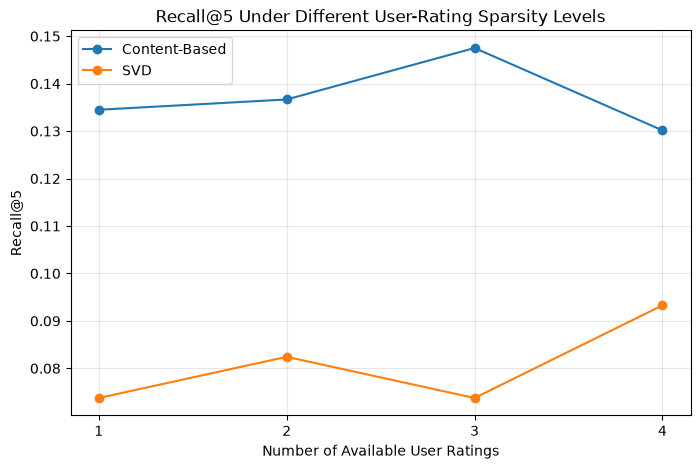

In [149]:
plt.figure(figsize=(8, 5))

plt.plot(
    sparsity_results['History Size'],
    sparsity_results['Content Recall@5'],
    marker='o',
    label='Content-Based'
)

plt.plot(
    sparsity_results['History Size'],
    sparsity_results['SVD Recall@5'],
    marker='o',
    label='SVD'
)

plt.xlabel('Number of Available User Ratings')
plt.ylabel('Recall@5')
plt.title('Recall@5 Under Different User-Rating Sparsity Levels')

plt.xticks(SPARSITY_LEVELS)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [150]:
# Random seeds for repeated sparsity experiments

EXPERIMENT_SEEDS = [42, 7, 21, 84, 100]

print("Number of experiment repetitions:", len(EXPERIMENT_SEEDS))
print("Sparsity levels:", SPARSITY_LEVELS)
print(
    "Total model conditions:",
    len(EXPERIMENT_SEEDS) * len(SPARSITY_LEVELS)
)

Number of experiment repetitions: 5
Sparsity levels: [1, 2, 3, 4]
Total model conditions: 20


In [151]:
# Repeat Content-Based sparsity experiment across multiple random seeds

repeated_content_results = []

for seed in EXPERIMENT_SEEDS:

    rng = np.random.default_rng(seed)

    # Create a new random ordering of each user's training history
    seed_user_rating_order = {}

    for uid in controlled_test_df['User-ID'].unique():

        user_history = controlled_train_df[
            controlled_train_df['User-ID'] == uid
        ]

        shuffled_indices = rng.permutation(user_history.index)

        seed_user_rating_order[uid] = shuffled_indices.tolist()

    # Test each sparsity level
    for history_size in SPARSITY_LEVELS:

        precision_scores = []
        recall_scores = []

        for uid in controlled_test_df['User-ID'].unique():

            selected_indices = (
                seed_user_rating_order[uid][:history_size]
            )

            sparse_history = controlled_train_df.loc[
                selected_indices
            ]

            relevant_book = controlled_test_df[
                controlled_test_df['User-ID'] == uid
            ]['ISBN'].iloc[0]

            seen_books = set(sparse_history['ISBN'])

            top_book = (
                sparse_history
                .sort_values('Book-Rating', ascending=False)
                .iloc[0]['ISBN']
            )

            seed_idx = controlled_book_indices[top_book]

            candidate_books = [
                book for book in common_books
                if book not in seen_books
            ]

            scored_books = []

            for book in candidate_books:

                candidate_idx = controlled_book_indices[book]

                similarity = controlled_cos_sim[
                    seed_idx,
                    candidate_idx
                ]

                scored_books.append(
                    (book, similarity)
                )

            scored_books.sort(
                key=lambda x: x[1],
                reverse=True
            )

            top_k = [
                book for book, score
                in scored_books[:K]
            ]

            hit = relevant_book in top_k

            precision_scores.append(int(hit) / K)
            recall_scores.append(int(hit))

        repeated_content_results.append({
            'Seed': seed,
            'History Size': history_size,
            'Precision@5': np.mean(precision_scores),
            'Recall@5': np.mean(recall_scores)
        })

        print(
            f"Seed={seed}, History={history_size}: "
            f"P@5={np.mean(precision_scores):.4f}, "
            f"R@5={np.mean(recall_scores):.4f}"
        )

Seed=42, History=1: P@5=0.0269, R@5=0.1345
Seed=42, History=2: P@5=0.0273, R@5=0.1367
Seed=42, History=3: P@5=0.0295, R@5=0.1475
Seed=42, History=4: P@5=0.0260, R@5=0.1302
Seed=7, History=1: P@5=0.0200, R@5=0.0998
Seed=7, History=2: P@5=0.0208, R@5=0.1041
Seed=7, History=3: P@5=0.0226, R@5=0.1128
Seed=7, History=4: P@5=0.0221, R@5=0.1106
Seed=21, History=1: P@5=0.0178, R@5=0.0889
Seed=21, History=2: P@5=0.0208, R@5=0.1041
Seed=21, History=3: P@5=0.0200, R@5=0.0998
Seed=21, History=4: P@5=0.0208, R@5=0.1041
Seed=84, History=1: P@5=0.0252, R@5=0.1258
Seed=84, History=2: P@5=0.0226, R@5=0.1128
Seed=84, History=3: P@5=0.0230, R@5=0.1150
Seed=84, History=4: P@5=0.0239, R@5=0.1193
Seed=100, History=1: P@5=0.0182, R@5=0.0911
Seed=100, History=2: P@5=0.0234, R@5=0.1171
Seed=100, History=3: P@5=0.0260, R@5=0.1302
Seed=100, History=4: P@5=0.0239, R@5=0.1193


In [152]:
repeated_content_df = pd.DataFrame(repeated_content_results)

content_summary = (
    repeated_content_df
    .groupby('History Size')
    .agg({
        'Precision@5': ['mean', 'std'],
        'Recall@5': ['mean', 'std']
    })
    .round(4)
)

content_summary

Precision@5      Recall@5     
                    mean  std     mean  std
History Size                               
1                   0.02 0.00     0.11 0.02
2                   0.02 0.00     0.12 0.01
3                   0.02 0.00     0.12 0.02
4                   0.02 0.00     0.12 0.01

In [153]:
content_summary = (
    repeated_content_df
    .groupby('History Size')
    .agg(
        Precision_mean=('Precision@5', 'mean'),
        Precision_std=('Precision@5', 'std'),
        Recall_mean=('Recall@5', 'mean'),
        Recall_std=('Recall@5', 'std')
    )
)

print(content_summary.to_string(float_format=lambda x: f'{x:.4f}'))

              Precision_mean  Precision_std  Recall_mean  Recall_std
History Size                                                        
1                     0.0216         0.0042       0.1080      0.0208
2                     0.0230         0.0027       0.1150      0.0134
3                     0.0242         0.0037       0.1210      0.0183
4                     0.0233         0.0020       0.1167      0.0099


In [154]:
# Repeat SVD sparsity experiment across multiple random seeds

repeated_svd_results = []

for seed in EXPERIMENT_SEEDS:

    rng = np.random.default_rng(seed)

    seed_user_rating_order = {}

    for uid in controlled_test_df['User-ID'].unique():

        user_history = controlled_train_df[
            controlled_train_df['User-ID'] == uid
        ]

        shuffled_indices = rng.permutation(user_history.index)

        seed_user_rating_order[uid] = shuffled_indices.tolist()

    for history_size in SPARSITY_LEVELS:

        # Build sparse training dataset
        selected_rows = []

        for uid in controlled_test_df['User-ID'].unique():

            selected_indices = (
                seed_user_rating_order[uid][:history_size]
            )

            selected_rows.append(
                controlled_train_df.loc[selected_indices]
            )

        sparse_train_df = pd.concat(
            selected_rows
        ).reset_index(drop=True)

        # Train SVD using only the available histories
        sparse_reader = Reader(rating_scale=(1, 10))

        sparse_data = Dataset.load_from_df(
            sparse_train_df[
                ['User-ID', 'ISBN', 'Book-Rating']
            ],
            sparse_reader
        )

        sparse_trainset = sparse_data.build_full_trainset()

        sparse_svd_model = SVD(
            n_factors=100,
            n_epochs=30,
            lr_all=0.005,
            reg_all=0.02,
            random_state=42
        )

        sparse_svd_model.fit(sparse_trainset)

        precision_scores = []
        recall_scores = []

        # Evaluate on the same held-out relevant books
        for uid in controlled_test_df['User-ID'].unique():

            relevant_book = controlled_test_df[
                controlled_test_df['User-ID'] == uid
            ]['ISBN'].iloc[0]

            selected_indices = (
                seed_user_rating_order[uid][:history_size]
            )

            sparse_history = controlled_train_df.loc[
                selected_indices
            ]

            seen_books = set(sparse_history['ISBN'])

            candidate_books = [
                book for book in common_books
                if book not in seen_books
            ]

            predictions = [
                (
                    book,
                    sparse_svd_model.predict(uid, book).est
                )
                for book in candidate_books
            ]

            predictions.sort(
                key=lambda x: x[1],
                reverse=True
            )

            top_k = [
                book for book, score
                in predictions[:K]
            ]

            hit = relevant_book in top_k

            precision_scores.append(int(hit) / K)
            recall_scores.append(int(hit))

        precision_at_k = np.mean(precision_scores)
        recall_at_k = np.mean(recall_scores)

        repeated_svd_results.append({
            'Seed': seed,
            'History Size': history_size,
            'Precision@5': precision_at_k,
            'Recall@5': recall_at_k
        })

        print(
            f"Seed={seed}, History={history_size}: "
            f"P@5={precision_at_k:.4f}, "
            f"R@5={recall_at_k:.4f}"
        )

Seed=42, History=1: P@5=0.0148, R@5=0.0738
Seed=42, History=2: P@5=0.0165, R@5=0.0824
Seed=42, History=3: P@5=0.0148, R@5=0.0738
Seed=42, History=4: P@5=0.0187, R@5=0.0933
Seed=7, History=1: P@5=0.0265, R@5=0.1323
Seed=7, History=2: P@5=0.0234, R@5=0.1171
Seed=7, History=3: P@5=0.0169, R@5=0.0846
Seed=7, History=4: P@5=0.0152, R@5=0.0759
Seed=21, History=1: P@5=0.0134, R@5=0.0672
Seed=21, History=2: P@5=0.0182, R@5=0.0911
Seed=21, History=3: P@5=0.0148, R@5=0.0738
Seed=21, History=4: P@5=0.0161, R@5=0.0803
Seed=84, History=1: P@5=0.0178, R@5=0.0889
Seed=84, History=2: P@5=0.0195, R@5=0.0976
Seed=84, History=3: P@5=0.0182, R@5=0.0911
Seed=84, History=4: P@5=0.0156, R@5=0.0781
Seed=100, History=1: P@5=0.0161, R@5=0.0803
Seed=100, History=2: P@5=0.0182, R@5=0.0911
Seed=100, History=3: P@5=0.0178, R@5=0.0889
Seed=100, History=4: P@5=0.0165, R@5=0.0824


In [155]:
repeated_svd_df = pd.DataFrame(repeated_svd_results)

svd_summary = (
    repeated_svd_df
    .groupby('History Size')
    .agg(
        Precision_mean=('Precision@5', 'mean'),
        Precision_std=('Precision@5', 'std'),
        Recall_mean=('Recall@5', 'mean'),
        Recall_std=('Recall@5', 'std')
    )
)

print(
    svd_summary.to_string(
        float_format=lambda x: f'{x:.4f}'
    )
)

              Precision_mean  Precision_std  Recall_mean  Recall_std
History Size                                                        
1                     0.0177         0.0052       0.0885      0.0258
2                     0.0192         0.0026       0.0959      0.0131
3                     0.0165         0.0017       0.0824      0.0083
4                     0.0164         0.0014       0.0820      0.0068


In [156]:
final_sparsity_results = pd.DataFrame({
    'History Size': SPARSITY_LEVELS,

    'Content Recall Mean': content_summary['Recall_mean'].values,
    'Content Recall Std': content_summary['Recall_std'].values,

    'SVD Recall Mean': svd_summary['Recall_mean'].values,
    'SVD Recall Std': svd_summary['Recall_std'].values,

    'Content Precision Mean': content_summary['Precision_mean'].values,
    'SVD Precision Mean': svd_summary['Precision_mean'].values
})

print(
    final_sparsity_results.to_string(
        index=False,
        float_format=lambda x: f'{x:.4f}'
    )
)

 History Size  Content Recall Mean  Content Recall Std  SVD Recall Mean  SVD Recall Std  Content Precision Mean  SVD Precision Mean
            1               0.1080              0.0208           0.0885          0.0258                  0.0216              0.0177
            2               0.1150              0.0134           0.0959          0.0131                  0.0230              0.0192
            3               0.1210              0.0183           0.0824          0.0083                  0.0242              0.0165
            4               0.1167              0.0099           0.0820          0.0068                  0.0233              0.0164


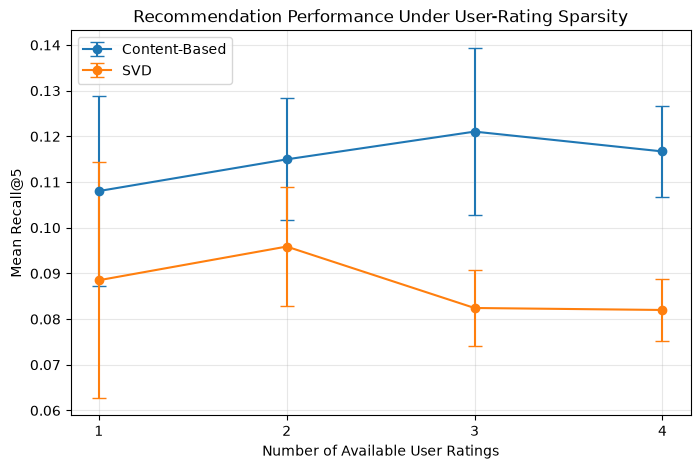

In [157]:
plt.figure(figsize=(8, 5))

plt.errorbar(
    final_sparsity_results['History Size'],
    final_sparsity_results['Content Recall Mean'],
    yerr=final_sparsity_results['Content Recall Std'],
    marker='o',
    capsize=5,
    label='Content-Based'
)

plt.errorbar(
    final_sparsity_results['History Size'],
    final_sparsity_results['SVD Recall Mean'],
    yerr=final_sparsity_results['SVD Recall Std'],
    marker='o',
    capsize=5,
    label='SVD'
)

plt.xlabel('Number of Available User Ratings')
plt.ylabel('Mean Recall@5')
plt.title('Recommendation Performance Under User-Rating Sparsity')

plt.xticks(SPARSITY_LEVELS)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Sparsity Experiment Results

To examine recommendation performance under sparse user histories, the number of available training ratings per user was varied from 1 to 4. The same 461 users and the same held-out relevant test items were used across all sparsity levels. A relevant item was defined as a held-out book with a rating of 7 or higher, and recommendation performance was evaluated at K = 5.

To reduce dependence on a single random selection of user ratings, the sparsity experiment was repeated using five random seeds. Mean Precision@5 and Recall@5 were then calculated across the five repetitions.

Across all four sparsity levels, the content-based model achieved higher mean Precision@5 and Recall@5 than the SVD collaborative filtering model. Content-based mean Recall@5 ranged from 0.1080 to 0.1210, while SVD mean Recall@5 ranged from 0.0820 to 0.0959.

The results did not show a consistent increase in performance as more ratings became available. Content-based performance increased slightly from 1 to 3 available ratings before decreasing at 4 ratings. SVD achieved its highest mean Recall@5 with 2 available ratings and decreased at 3 and 4 ratings. Therefore, the results do not support a simple conclusion that additional ratings always improved recommendation performance within the tested range.

The standard deviations also show that performance varied depending on which ratings were available to the models, particularly under very sparse conditions. These results should therefore be interpreted as preliminary evidence under the current experimental setup rather than proof that one recommendation method is universally superior.

## Experiment 2: Effect of Book-Popularity Thresholds

This experiment investigates how changing the minimum number of ratings required for a book to be included affects the performance of content-based filtering and SVD collaborative filtering.

Both algorithms will be evaluated using Precision@5 and Recall@5 under comparable conditions.

In [158]:
print(ratings_df.shape)
print(ratings_df.columns.tolist())

(1149780, 3)
['User-ID', 'ISBN', 'Book-Rating']


In [159]:
book_rating_counts = ratings_df.groupby("ISBN").size()

for threshold in [50, 100, 200, 300]:
    num_books = (book_rating_counts >= threshold).sum()
    print(f"Threshold {threshold}: {num_books} books")

Threshold 50: 2185 books
Threshold 100: 731 books
Threshold 200: 195 books
Threshold 300: 82 books


In [160]:
explicit_ratings = ratings_df[ratings_df["Book-Rating"] > 0]

explicit_counts = explicit_ratings.groupby("ISBN").size()

for threshold in [50, 100, 200, 300]:
    num_books = (explicit_counts >= threshold).sum()
    print(f"Threshold {threshold}: {num_books} books")

Threshold 50: 537 books
Threshold 100: 140 books
Threshold 200: 32 books
Threshold 300: 8 books


In [161]:
for threshold in [50, 100, 200]:
    eligible_books = explicit_counts[
        explicit_counts >= threshold
    ].index

    filtered = explicit_ratings[
        explicit_ratings["ISBN"].isin(eligible_books)
    ]

    user_counts = filtered.groupby("User-ID").size()
    eligible_users = (user_counts >= 5).sum()

    print(
        f"Threshold {threshold}: "
        f"{len(eligible_books)} books, "
        f"{eligible_users} users with at least 5 ratings"
    )

Threshold 50: 537 books, 2212 users with at least 5 ratings
Threshold 100: 140 books, 883 users with at least 5 ratings
Threshold 200: 32 books, 128 users with at least 5 ratings


In [162]:
thresholds = [50, 100, 200]
eligible_user_sets = []

for threshold in thresholds:
    eligible_books = explicit_counts[
        explicit_counts >= threshold
    ].index

    filtered = explicit_ratings[
        explicit_ratings["ISBN"].isin(eligible_books)
    ]

    user_counts = filtered.groupby("User-ID").size()

    eligible_user_sets.append(
        set(user_counts[user_counts >= 5].index)
    )

shared_users = set.intersection(*eligible_user_sets)

print("Users eligible at all thresholds:", len(shared_users))

Users eligible at all thresholds: 128


In [163]:
for threshold in [50, 100, 200]:
    eligible_books = explicit_counts[
        explicit_counts >= threshold
    ].index

    filtered = explicit_ratings[
        explicit_ratings["ISBN"].isin(eligible_books)
        & explicit_ratings["User-ID"].isin(shared_users)
    ]

    relevant = filtered[
        filtered["Book-Rating"] >= 7
    ]

    users_with_relevant_books = relevant["User-ID"].nunique()

    print(
        f"Threshold {threshold}: "
        f"{users_with_relevant_books} users with relevant books"
    )

Threshold 50: 127 users with relevant books
Threshold 100: 127 users with relevant books
Threshold 200: 127 users with relevant books


In [164]:
evaluation_users = sorted(
    set(
        explicit_ratings.loc[
            (explicit_ratings["ISBN"].isin(
                explicit_counts[explicit_counts >= 200].index
            ))
            & (explicit_ratings["Book-Rating"] >= 7),
            "User-ID"
        ]
    ) & shared_users
)

print("Number of evaluation users:", len(evaluation_users))

Number of evaluation users: 127


In [165]:
import numpy as np

rng = np.random.default_rng(42)

# Books that qualify at the strictest threshold
books_200 = set(
    explicit_counts[explicit_counts >= 200].index
)

test_rows = []

for user in evaluation_users:
    liked_books = explicit_ratings[
        (explicit_ratings["User-ID"] == user)
        & (explicit_ratings["ISBN"].isin(books_200))
        & (explicit_ratings["Book-Rating"] >= 7)
    ]

    chosen = liked_books.iloc[
        rng.integers(len(liked_books))
    ]

    test_rows.append(chosen)

test_df = pd.DataFrame(test_rows).reset_index(drop=True)

print("Test users:", test_df["User-ID"].nunique())
print("Held-out books:", len(test_df))
print("Minimum test rating:", test_df["Book-Rating"].min())

Test users: 127
Held-out books: 127
Minimum test rating: 7


In [166]:
# Remove held-out ratings from the training data
test_pairs = pd.MultiIndex.from_frame(
    test_df[["User-ID", "ISBN"]]
)

rating_pairs = pd.MultiIndex.from_frame(
    explicit_ratings[["User-ID", "ISBN"]]
)

train_df = explicit_ratings.loc[
    ~rating_pairs.isin(test_pairs)
].copy()

# Verify that none of the test ratings remain
train_pairs = pd.MultiIndex.from_frame(
    train_df[["User-ID", "ISBN"]]
)

leakage = train_pairs.isin(test_pairs).sum()

print("Training ratings:", len(train_df))
print("Test ratings:", len(test_df))
print("Test ratings remaining in training:", leakage)

Training ratings: 433544
Test ratings: 127
Test ratings remaining in training: 0


In [167]:
for threshold in [50, 100, 200]:
    eligible_books = explicit_counts[
        explicit_counts >= threshold
    ].index

    filtered_train = train_df[
        train_df["ISBN"].isin(eligible_books)
        & train_df["User-ID"].isin(evaluation_users)
    ]

    counts = filtered_train.groupby("User-ID").size()

    print(
        f"Threshold {threshold}: "
        f"{len(eligible_books)} books, "
        f"{len(filtered_train)} training ratings, "
        f"{(counts >= 4).sum()} users with at least 4 training ratings"
    )

Threshold 50: 537 books, 3641 training ratings, 127 users with at least 4 training ratings
Threshold 100: 140 books, 1715 training ratings, 127 users with at least 4 training ratings
Threshold 200: 32 books, 691 training ratings, 127 users with at least 4 training ratings


In [168]:
import inspect

functions = [
    (name, obj)
    for name, obj in globals().items()
    if inspect.isfunction(obj)
]

for name, obj in functions:
    print(name)

open
linear_kernel
train_test_split
scatter_matrix
cosine_similarity
mean_squared_error
suprise_split
recommend_for_user
evaluate_svd_top_k
obj


In [169]:
import inspect

for name in [
    "recommend_for_user",
    "evaluate_svd_top_k",
    "get_top_n_recommendations"
]:
    func = globals().get(name)

    if func is None:
        print(f"{name} has not been defined yet")
        continue

    print(f"\n{'=' * 20} {name} {'=' * 20}")
    print(inspect.getsource(func))


==================== recommend_for_user ====================
def recommend_for_user(user_id, top_n=5):
    user_ratings = train_df[train_df['User-ID'] == user_id].sort_values(by='Book-Rating', ascending=False)
    if user_ratings.empty:
        return []

    # Only consider books present in the similarity matrix
    top_books = user_ratings[user_ratings['ISBN'].isin(df_books['ISBN'])]
    if top_books.empty:
        return []

    top_book = top_books.iloc[0]['ISBN']
    if top_book not in book_indices:
        return []

    idx = book_indices[top_book]
    sim_scores = list(enumerate(cos_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    # Filter out books already rated by the user
    sim_scores = [i for i in sim_scores if df_books.iloc[i[0]]['ISBN'] not in user_ratings['ISBN'].values]
    top_indices = [i[0] for i in sim_scores[:top_n]]

    # Return recommended books with titles
    recommended_books = df_books.iloc[top_indices][['ISBN', 'Book-

In [170]:
import inspect

for name in [
    "recommend_for_user",
    "evaluate_svd_top_k",
    "get_top_n_recommendations"
]:
    func = globals().get(name)

    if func is None:
        print(f"{name} has not been defined yet")
        continue

    print(name, inspect.signature(func))

recommend_for_user (user_id, top_n=5)
evaluate_svd_top_k (model, train_df, test_df, all_books, k=5, relevance_threshold=7, max_users=200)
get_top_n_recommendations has not been defined yet


In [171]:
print(books_df.columns.tolist())
print(books_df[["ISBN", "Book-Title", "Book-Author", "Publisher"]].head(3))

['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-S', 'Image-URL-M', 'Image-URL-L']
         ISBN            Book-Title           Book-Author  \
0  0195153448   Classical Mythology    Mark P. O. Morford   
1  0002005018          Clara Callan  Richard Bruce Wright   
2  0060973129  Decision in Normandy          Carlo D'Este   

                 Publisher  
0  Oxford University Press  
1    HarperFlamingo Canada  
2          HarperPerennial  


In [172]:
# Prepare book metadata for the popularity experiment
popularity_books = books_df[
    ["ISBN", "Book-Title", "Book-Author", "Publisher"]
].drop_duplicates(subset="ISBN").copy()

# Fill missing information
for col in ["Book-Title", "Book-Author", "Publisher"]:
    popularity_books[col] = popularity_books[col].fillna("")

# Combine metadata into one text field for TF-IDF
popularity_books["content"] = (
    popularity_books["Book-Title"].astype(str) + " " +
    popularity_books["Book-Author"].astype(str) + " " +
    popularity_books["Publisher"].astype(str)
)

print("Books with metadata:", len(popularity_books))
print(popularity_books[["ISBN", "content"]].head(3))

Books with metadata: 271360
         ISBN                                            content
0  0195153448  Classical Mythology Mark P. O. Morford Oxford ...
1  0002005018  Clara Callan Richard Bruce Wright HarperFlamin...
2  0060973129  Decision in Normandy Carlo D'Este HarperPerennial


In [173]:
# Build separate content-based models for each threshold
popularity_content_models = {}

for threshold in [50, 100, 200]:
    eligible_isbns = set(
        explicit_counts[explicit_counts >= threshold].index
    )

    catalog = popularity_books[
        popularity_books["ISBN"].isin(eligible_isbns)
    ].reset_index(drop=True)

    vectorizer = TfidfVectorizer(
        stop_words="english",
        max_features=TFIDF_MAX_FEATURES
    )

    tfidf_matrix = vectorizer.fit_transform(catalog["content"])
    similarity = cosine_similarity(tfidf_matrix)

    popularity_content_models[threshold] = {
        "catalog": catalog,
        "similarity": similarity,
        "indices": {
            isbn: i for i, isbn in enumerate(catalog["ISBN"])
        }
    }

    print(
        f"Threshold {threshold}: "
        f"{len(catalog)} books, "
        f"similarity matrix {similarity.shape}"
    )

Threshold 50: 531 books, similarity matrix (531, 531)
Threshold 100: 139 books, similarity matrix (139, 139)
Threshold 200: 31 books, similarity matrix (31, 31)


In [174]:
for threshold in [50, 100, 200]:
    catalog_isbns = set(
        popularity_content_models[threshold]["catalog"]["ISBN"]
    )

    missing_test = test_df[
        ~test_df["ISBN"].isin(catalog_isbns)
    ]

    print(
        f"Threshold {threshold}: "
        f"{len(missing_test)} hidden test books missing"
    )

Threshold 50: 9 hidden test books missing
Threshold 100: 9 hidden test books missing
Threshold 200: 9 hidden test books missing


In [175]:
# Keep test books available at every threshold
common_catalog = set.intersection(
    *[
        set(popularity_content_models[t]["catalog"]["ISBN"])
        for t in [50, 100, 200]
    ]
)

pop_test_df = test_df[
    test_df["ISBN"].isin(common_catalog)
].copy()

pop_evaluation_users = sorted(
    pop_test_df["User-ID"].unique()
)

print("Original test users:", len(test_df))
print("Usable test users:", len(pop_evaluation_users))
print("Excluded test users:", len(test_df) - len(pop_test_df))

Original test users: 127
Usable test users: 118
Excluded test users: 9


In [176]:
for threshold in [50, 100, 200]:
    catalog_isbns = set(
        popularity_content_models[threshold]["catalog"]["ISBN"]
    )

    user_train = train_df[
        train_df["User-ID"].isin(pop_evaluation_users)
        & train_df["ISBN"].isin(catalog_isbns)
    ]

    counts = user_train.groupby("User-ID").size()

    print(
        f"Threshold {threshold}: "
        f"{(counts >= 4).sum()} users with at least 4 training ratings, "
        f"minimum = {counts.reindex(pop_evaluation_users, fill_value=0).min()}"
    )

Threshold 50: 118 users with at least 4 training ratings, minimum = 4
Threshold 100: 118 users with at least 4 training ratings, minimum = 4
Threshold 200: 108 users with at least 4 training ratings, minimum = 3


In [177]:
# Find users with at least 4 training ratings at every threshold
valid_user_sets = []

for threshold in [50, 100, 200]:
    catalog_isbns = set(
        popularity_content_models[threshold]["catalog"]["ISBN"]
    )

    user_train = train_df[
        train_df["User-ID"].isin(pop_evaluation_users)
        & train_df["ISBN"].isin(catalog_isbns)
    ]

    counts = user_train.groupby("User-ID").size()

    valid_user_sets.append(
        set(counts[counts >= 4].index)
    )

final_users = sorted(set.intersection(*valid_user_sets))

final_test_df = pop_test_df[
    pop_test_df["User-ID"].isin(final_users)
].copy()

print("Final evaluation users:", len(final_users))
print("Final hidden test ratings:", len(final_test_df))

Final evaluation users: 108
Final hidden test ratings: 108


In [178]:
def recommend_popularity_content(user_id, threshold, top_n=5):
    model = popularity_content_models[threshold]

    catalog = model["catalog"]
    similarity = model["similarity"]
    indices = model["indices"]

    # Get this user's training ratings within the catalog
    user_history = train_df[
        (train_df["User-ID"] == user_id)
        & (train_df["ISBN"].isin(indices))
    ].sort_values("Book-Rating", ascending=False)

    if user_history.empty:
        return []

    # Use the user's highest-rated book as their profile
    favorite_isbn = user_history.iloc[0]["ISBN"]
    favorite_idx = indices[favorite_isbn]

    # Rank books by similarity to the favorite
    scores = similarity[favorite_idx]

    # Exclude books already rated by this user
    rated_books = set(user_history["ISBN"])

    ranked_indices = sorted(
        range(len(catalog)),
        key=lambda i: (-scores[i], i)
    )

    recommendations = [
        catalog.iloc[i]["ISBN"]
        for i in ranked_indices
        if catalog.iloc[i]["ISBN"] not in rated_books
    ]

    return recommendations[:top_n]


# Quick test with one user
example_user = final_users[0]

for threshold in [50, 100, 200]:
    recommendations = recommend_popularity_content(
        example_user, threshold, top_n=5
    )

    print(f"Threshold {threshold}: {recommendations}")

Threshold 50: ['038082101X', '0061097314', '0380789035', '0399150897', '0060502258']
Threshold 100: ['0439139597', '0439064872', '0439064864', '0590353403', '0439136350']
Threshold 200: ['0385504209', '0156027321', '0142001740', '0971880107', '0446310786']


In [179]:
content_results = []

for threshold in [50, 100, 200]:
    hits = 0

    for _, row in final_test_df.iterrows():
        user_id = row["User-ID"]
        hidden_book = row["ISBN"]

        recommendations = recommend_popularity_content(
            user_id, threshold, top_n=5
        )

        if hidden_book in recommendations:
            hits += 1

    recall = hits / len(final_test_df)
    precision = hits / (len(final_test_df) * 5)

    content_results.append({
        "Threshold": threshold,
        "Hits": hits,
        "Precision@5": precision,
        "Recall@5": recall
    })

content_results_df = pd.DataFrame(content_results)

print(content_results_df.to_string(index=False))

 Threshold  Hits  Precision@5  Recall@5
        50     3         0.01      0.03
       100     8         0.01      0.07
       200    25         0.05      0.23


In [180]:
from surprise import Dataset, Reader, SVD

reader = Reader(rating_scale=(1, 10))

print("SVD setup ready!")

SVD setup ready!


In [181]:
popularity_svd_models = {}

for threshold in [50, 100, 200]:
    # Use the same book catalog as content-based filtering
    catalog_isbns = set(
        popularity_content_models[threshold]["catalog"]["ISBN"]
    )

    # Keep training ratings for books in this catalog
    svd_train = train_df[
        train_df["ISBN"].isin(catalog_isbns)
    ].copy()

    # Convert ratings into Surprise format
    data = Dataset.load_from_df(
        svd_train[["User-ID", "ISBN", "Book-Rating"]],
        reader
    )

    training_set = data.build_full_trainset()

    # Train SVD using our Midterm hyperparameters
    model = SVD(
        n_factors=100,
        n_epochs=30,
        lr_all=0.005,
        reg_all=0.02,
        random_state=42
    )

    model.fit(training_set)

    popularity_svd_models[threshold] = model

    print(
        f"Threshold {threshold}: "
        f"SVD trained on {len(svd_train)} ratings"
    )

Threshold 50: SVD trained on 49447 ratings
Threshold 100: SVD trained on 23050 ratings
Threshold 200: SVD trained on 8553 ratings


In [182]:
def recommend_popularity_svd(user_id, threshold, top_n=5):
    model = popularity_svd_models[threshold]

    catalog_isbns = list(
        popularity_content_models[threshold]["catalog"]["ISBN"]
    )

    # Exclude books the user has already rated
    rated_books = set(
        train_df.loc[
            train_df["User-ID"] == user_id, "ISBN"
        ]
    )

    candidate_books = [
        isbn for isbn in catalog_isbns
        if isbn not in rated_books
    ]

    # Predict how much the user might like each book
    predictions = [
        (isbn, model.predict(user_id, isbn).est)
        for isbn in candidate_books
    ]

    # Sort from highest to lowest predicted rating
    predictions.sort(key=lambda x: (-x[1], x[0]))

    return [
        isbn for isbn, score in predictions[:top_n]
    ]


# Test with one user
example_user = final_users[0]

for threshold in [50, 100, 200]:
    recommendations = recommend_popularity_svd(
        example_user, threshold, top_n=5
    )

    print(f"Threshold {threshold}: {recommendations}")

Threshold 50: ['0590353403', '0440214041', '0684833395', '0060930535', '0345339703']
Threshold 100: ['0142001740', '0140067477', '0449212602', '0345342968', '0345339703']
Threshold 200: ['0446310786', '0060930535', '0446605239', '044021145X', '0375727345']


In [183]:
svd_results = []

for threshold in [50, 100, 200]:
    hits = 0

    for _, row in final_test_df.iterrows():
        user_id = row["User-ID"]
        hidden_book = row["ISBN"]

        recommendations = recommend_popularity_svd(
            user_id, threshold, top_n=5
        )

        if hidden_book in recommendations:
            hits += 1

    recall = hits / len(final_test_df)
    precision = hits / (len(final_test_df) * 5)

    svd_results.append({
        "Threshold": threshold,
        "Hits": hits,
        "Precision@5": precision,
        "Recall@5": recall
    })

svd_results_df = pd.DataFrame(svd_results)

print(svd_results_df.to_string(index=False))

 Threshold  Hits  Precision@5  Recall@5
        50     3         0.01      0.03
       100     9         0.02      0.08
       200    23         0.04      0.21


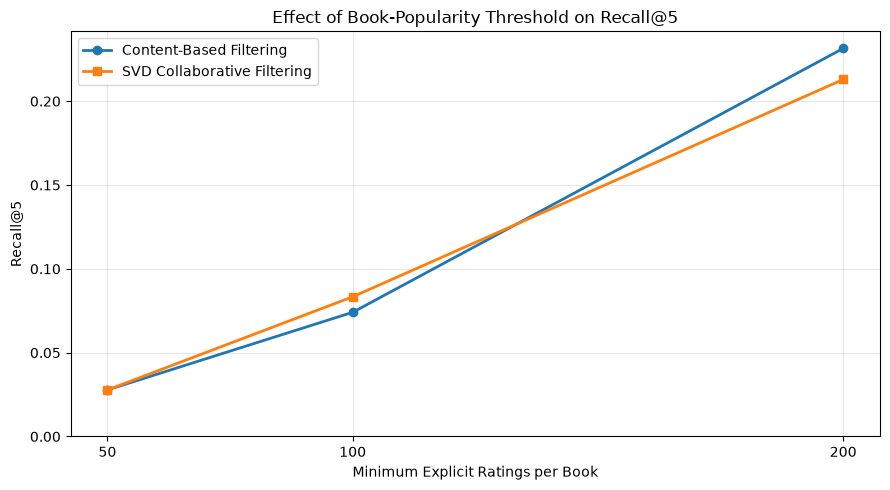

In [184]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    content_results_df["Threshold"],
    content_results_df["Recall@5"],
    marker="o",
    linewidth=2,
    label="Content-Based Filtering"
)

plt.plot(
    svd_results_df["Threshold"],
    svd_results_df["Recall@5"],
    marker="s",
    linewidth=2,
    label="SVD Collaborative Filtering"
)

plt.xlabel("Minimum Explicit Ratings per Book")
plt.ylabel("Recall@5")
plt.title("Effect of Book-Popularity Threshold on Recall@5")
plt.xticks([50, 100, 200])
plt.ylim(bottom=0)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [185]:
for threshold in [50, 100, 200]:
    catalog = set(
        popularity_content_models[threshold]["catalog"]["ISBN"]
    )

    candidate_counts = []

    for user_id in final_users:
        rated = set(
            train_df.loc[
                train_df["User-ID"] == user_id, "ISBN"
            ]
        )

        candidates = catalog - rated
        candidate_counts.append(len(candidates))

    print(
        f"Threshold {threshold}: "
        f"Average candidates = {sum(candidate_counts)/len(candidate_counts):.1f}, "
        f"Minimum candidates = {min(candidate_counts)}"
    )

Threshold 50: Average candidates = 501.7, Minimum candidates = 203
Threshold 100: Average candidates = 125.2, Minimum candidates = 49
Threshold 200: Average candidates = 25.5, Minimum candidates = 11


In [186]:
import numpy as np

rng = np.random.default_rng(42)
random_results = []

for threshold in [50, 100, 200]:
    catalog = set(
        popularity_content_models[threshold]["catalog"]["ISBN"]
    )

    hits = 0
    total_candidates = 0

    for _, row in final_test_df.iterrows():
        user_id = row["User-ID"]
        hidden_book = row["ISBN"]

        rated = set(
            train_df.loc[
                train_df["User-ID"] == user_id, "ISBN"
            ]
        )

        candidates = sorted(catalog - rated)
        total_candidates += len(candidates)

        recommendations = rng.choice(
            candidates,
            size=min(5, len(candidates)),
            replace=False
        )

        if hidden_book in recommendations:
            hits += 1

    random_results.append({
        "Threshold": threshold,
        "Random Hits": hits,
        "Random Recall@5": hits / len(final_test_df),
        "Average Candidates": total_candidates / len(final_test_df)
    })

random_results_df = pd.DataFrame(random_results)
print(random_results_df.to_string(index=False))

 Threshold  Random Hits  Random Recall@5  Average Candidates
        50            0             0.00              501.72
       100            1             0.01              125.19
       200           24             0.22               25.54


In [187]:
expected_random_results = []

for threshold in [50, 100, 200]:
    catalog = set(
        popularity_content_models[threshold]["catalog"]["ISBN"]
    )

    probabilities = []

    for _, row in final_test_df.iterrows():
        user_id = row["User-ID"]

        rated = set(
            train_df.loc[
                train_df["User-ID"] == user_id, "ISBN"
            ]
        )

        candidates = catalog - rated

        # Probability that random top-5 includes the hidden book
        probability = min(5, len(candidates)) / len(candidates)
        probabilities.append(probability)

    expected_random_results.append({
        "Threshold": threshold,
        "Expected Random Recall@5": np.mean(probabilities)
    })

expected_random_df = pd.DataFrame(expected_random_results)

print(expected_random_df.to_string(index=False))

 Threshold  Expected Random Recall@5
        50                      0.01
       100                      0.04
       200                      0.20


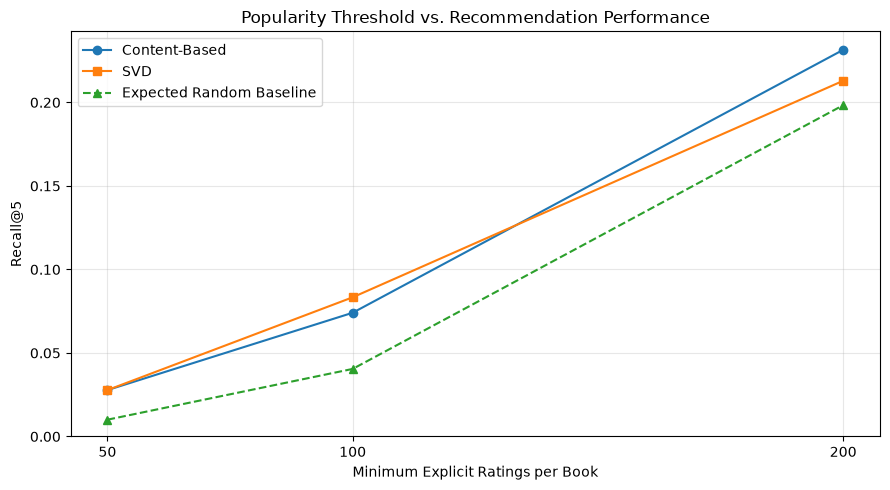

In [188]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    content_results_df["Threshold"],
    content_results_df["Recall@5"],
    marker="o",
    label="Content-Based"
)

plt.plot(
    svd_results_df["Threshold"],
    svd_results_df["Recall@5"],
    marker="s",
    label="SVD"
)

plt.plot(
    expected_random_df["Threshold"],
    expected_random_df["Expected Random Recall@5"],
    marker="^",
    linestyle="--",
    label="Expected Random Baseline"
)

plt.xlabel("Minimum Explicit Ratings per Book")
plt.ylabel("Recall@5")
plt.title("Popularity Threshold vs. Recommendation Performance")
plt.xticks([50, 100, 200])
plt.ylim(bottom=0)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [189]:
# Recalculate popularity using training ratings only
train_popularity_counts = train_df.groupby("ISBN").size()

for threshold in [50, 100, 200]:
    original_books = set(
        explicit_counts[explicit_counts >= threshold].index
    )

    training_books = set(
        train_popularity_counts[
            train_popularity_counts >= threshold
        ].index
    )

    print(
        f"Threshold {threshold}: "
        f"{len(original_books)} original books, "
        f"{len(training_books)} training-only books, "
        f"{len(original_books - training_books)} books changed"
    )

Threshold 50: 537 original books, 537 training-only books, 0 books changed
Threshold 100: 140 original books, 140 training-only books, 0 books changed
Threshold 200: 32 original books, 30 training-only books, 2 books changed


In [190]:
original_200 = set(
    explicit_counts[explicit_counts >= 200].index
)

training_200 = set(
    train_popularity_counts[
        train_popularity_counts >= 200
    ].index
)

changed_books = sorted(original_200 - training_200)

print("Books that no longer qualify:")
for isbn in changed_books:
    print(
        isbn,
        "Original ratings:", explicit_counts[isbn],
        "Training ratings:", train_popularity_counts[isbn]
    )

Books that no longer qualify:
0345370775 Original ratings: 200 Training ratings: 199
0385484518 Original ratings: 200 Training ratings: 194


In [191]:
# Build corrected catalogs using training data only
corrected_catalogs = {}

for threshold in [50, 100, 200]:
    eligible_isbns = set(
        train_popularity_counts[
            train_popularity_counts >= threshold
        ].index
    )

    catalog = popularity_books[
        popularity_books["ISBN"].isin(eligible_isbns)
    ].reset_index(drop=True)

    corrected_catalogs[threshold] = catalog

    print(
        f"Threshold {threshold}: "
        f"{len(catalog)} books with metadata"
    )

Threshold 50: 531 books with metadata
Threshold 100: 139 books with metadata
Threshold 200: 29 books with metadata


In [192]:
# Books available at all three corrected thresholds
common_corrected_books = set.intersection(
    *[
        set(corrected_catalogs[t]["ISBN"])
        for t in [50, 100, 200]
    ]
)

# Keep only test books available in every catalog
corrected_test_df = final_test_df[
    final_test_df["ISBN"].isin(common_corrected_books)
].copy()

print("Previous test users:", len(final_test_df))
print("Remaining test users:", len(corrected_test_df))
print(
    "Excluded users:",
    len(final_test_df) - len(corrected_test_df)
)

Previous test users: 108
Remaining test users: 101
Excluded users: 7


In [193]:
valid_corrected_users = []

for threshold in [50, 100, 200]:
    catalog_isbns = set(corrected_catalogs[threshold]["ISBN"])

    filtered = train_df[
        train_df["User-ID"].isin(corrected_test_df["User-ID"])
        & train_df["ISBN"].isin(catalog_isbns)
    ]

    counts = filtered.groupby("User-ID").size()

    valid_users = set(counts[counts >= 4].index)
    valid_corrected_users.append(valid_users)

    print(
        f"Threshold {threshold}: "
        f"{len(valid_users)} users with at least 4 training ratings"
    )

corrected_users = sorted(set.intersection(*valid_corrected_users))

print("Users eligible at all thresholds:", len(corrected_users))

Threshold 50: 101 users with at least 4 training ratings
Threshold 100: 101 users with at least 4 training ratings
Threshold 200: 94 users with at least 4 training ratings
Users eligible at all thresholds: 94


In [194]:
# Final corrected test set
corrected_final_test_df = corrected_test_df[
    corrected_test_df["User-ID"].isin(corrected_users)
].copy()

print("Final evaluation users:",
      corrected_final_test_df["User-ID"].nunique())

print("Hidden test ratings:",
      len(corrected_final_test_df))

print("All ratings relevant:",
      (corrected_final_test_df["Book-Rating"] >= 7).all())

print("Unique user-book pairs:",
      corrected_final_test_df[["User-ID", "ISBN"]]
      .drop_duplicates().shape[0])

Final evaluation users: 94
Hidden test ratings: 94
All ratings relevant: True
Unique user-book pairs: 94


In [195]:
corrected_content_models = {}

for threshold in [50, 100, 200]:
    catalog = corrected_catalogs[threshold]

    vectorizer = TfidfVectorizer(
        stop_words="english",
        max_features=TFIDF_MAX_FEATURES
    )

    tfidf_matrix = vectorizer.fit_transform(
        catalog["content"]
    )

    similarity = cosine_similarity(tfidf_matrix)

    corrected_content_models[threshold] = {
        "catalog": catalog,
        "similarity": similarity,
        "indices": {
            isbn: i
            for i, isbn in enumerate(catalog["ISBN"])
        }
    }

    print(
        f"Threshold {threshold}: "
        f"similarity matrix {similarity.shape}"
    )

Threshold 50: similarity matrix (531, 531)
Threshold 100: similarity matrix (139, 139)
Threshold 200: similarity matrix (29, 29)


In [196]:
def recommend_corrected_content(user_id, threshold, top_n=5):
    model = corrected_content_models[threshold]

    catalog = model["catalog"]
    similarity = model["similarity"]
    indices = model["indices"]

    # Find books this user has rated in the corrected catalog
    user_history = train_df[
        (train_df["User-ID"] == user_id)
        & (train_df["ISBN"].isin(indices))
    ].sort_values("Book-Rating", ascending=False)

    if user_history.empty:
        return []

    # Use the user's highest-rated book
    favorite_isbn = user_history.iloc[0]["ISBN"]
    favorite_idx = indices[favorite_isbn]

    scores = similarity[favorite_idx]

    # Don't recommend books the user has already rated
    rated_books = set(user_history["ISBN"])

    ranked_indices = sorted(
        range(len(catalog)),
        key=lambda i: (-scores[i], i)
    )

    return [
        catalog.iloc[i]["ISBN"]
        for i in ranked_indices
        if catalog.iloc[i]["ISBN"] not in rated_books
    ][:top_n]


# Test the function on one user
sample_user = corrected_users[0]

for threshold in [50, 100, 200]:
    recommendations = recommend_corrected_content(
        sample_user, threshold
    )

    print(
        f"Threshold {threshold}: "
        f"{len(recommendations)} recommendations"
    )

Threshold 50: 5 recommendations
Threshold 100: 5 recommendations
Threshold 200: 5 recommendations


In [197]:
corrected_content_results = []

for threshold in [50, 100, 200]:
    hits = 0

    for _, row in corrected_final_test_df.iterrows():
        user_id = row["User-ID"]
        hidden_book = row["ISBN"]

        recommendations = recommend_corrected_content(
            user_id, threshold, top_n=5
        )

        if hidden_book in recommendations:
            hits += 1

    n_users = len(corrected_final_test_df)

    precision = hits / (n_users * 5)
    recall = hits / n_users

    corrected_content_results.append({
        "Threshold": threshold,
        "Hits": hits,
        "Precision@5": precision,
        "Recall@5": recall
    })

corrected_content_results_df = pd.DataFrame(
    corrected_content_results
)

print(corrected_content_results_df.to_string(index=False))

 Threshold  Hits  Precision@5  Recall@5
        50     2         0.00      0.02
       100     5         0.01      0.05
       200    22         0.05      0.23


In [198]:
corrected_svd_models = {}

for threshold in [50, 100, 200]:
    catalog_isbns = set(corrected_catalogs[threshold]["ISBN"])

    svd_train = train_df[
        train_df["ISBN"].isin(catalog_isbns)
    ].copy()

    surprise_data = Dataset.load_from_df(
        svd_train[["User-ID", "ISBN", "Book-Rating"]],
        reader
    )

    trainset = surprise_data.build_full_trainset()

    model = SVD(
        n_factors=100,
        n_epochs=30,
        lr_all=0.005,
        reg_all=0.02,
        random_state=42
    )

    model.fit(trainset)

    corrected_svd_models[threshold] = model

    print(
        f"Threshold {threshold}: "
        f"trained on {len(svd_train)} ratings"
    )

Threshold 50: trained on 49447 ratings
Threshold 100: trained on 23050 ratings
Threshold 200: trained on 8160 ratings


In [199]:
def recommend_corrected_svd(user_id, threshold, top_n=5):
    model = corrected_svd_models[threshold]

    catalog_isbns = list(
        corrected_catalogs[threshold]["ISBN"]
    )

    # Books the user has already rated
    rated_books = set(
        train_df.loc[
            train_df["User-ID"] == user_id, "ISBN"
        ]
    )

    # Only recommend books the user hasn't rated
    candidate_books = [
        isbn for isbn in catalog_isbns
        if isbn not in rated_books
    ]

    # Predict how much the user would like each book
    predictions = [
        (isbn, model.predict(user_id, isbn).est)
        for isbn in candidate_books
    ]

    # Rank books from highest to lowest predicted rating
    predictions.sort(
        key=lambda x: (-x[1], x[0])
    )

    return [
        isbn for isbn, score in predictions[:top_n]
    ]


# Test on one user
sample_user = corrected_users[0]

for threshold in [50, 100, 200]:
    recommendations = recommend_corrected_svd(
        sample_user, threshold
    )

    print(
        f"Threshold {threshold}: "
        f"{len(recommendations)} recommendations"
    )

Threshold 50: 5 recommendations
Threshold 100: 5 recommendations
Threshold 200: 5 recommendations


In [200]:
corrected_svd_results = []

for threshold in [50, 100, 200]:
    hits = 0

    for _, row in corrected_final_test_df.iterrows():
        user_id = row["User-ID"]
        hidden_book = row["ISBN"]

        recommendations = recommend_corrected_svd(
            user_id, threshold, top_n=5
        )

        if hidden_book in recommendations:
            hits += 1

    n_users = len(corrected_final_test_df)

    precision = hits / (n_users * 5)
    recall = hits / n_users

    corrected_svd_results.append({
        "Threshold": threshold,
        "Hits": hits,
        "Precision@5": precision,
        "Recall@5": recall
    })

corrected_svd_results_df = pd.DataFrame(
    corrected_svd_results
)

print(corrected_svd_results_df.to_string(index=False))

 Threshold  Hits  Precision@5  Recall@5
        50     3         0.01      0.03
       100     7         0.01      0.07
       200    30         0.06      0.32


In [201]:
corrected_random_results = []

for threshold in [50, 100, 200]:
    catalog_isbns = set(corrected_catalogs[threshold]["ISBN"])
    probabilities = []

    for _, row in corrected_final_test_df.iterrows():
        user_id = row["User-ID"]

        rated_books = set(
            train_df.loc[
                train_df["User-ID"] == user_id, "ISBN"
            ]
        )

        candidates = catalog_isbns - rated_books

        # Probability that 5 random recommendations
        # include the user's hidden book
        probability = min(5, len(candidates)) / len(candidates)

        probabilities.append(probability)

    expected_recall = sum(probabilities) / len(probabilities)

    corrected_random_results.append({
        "Threshold": threshold,
        "Expected Random Recall@5": expected_recall
    })

corrected_random_df = pd.DataFrame(corrected_random_results)

print(corrected_random_df.to_string(index=False))

 Threshold  Expected Random Recall@5
        50                      0.01
       100                      0.04
       200                      0.21


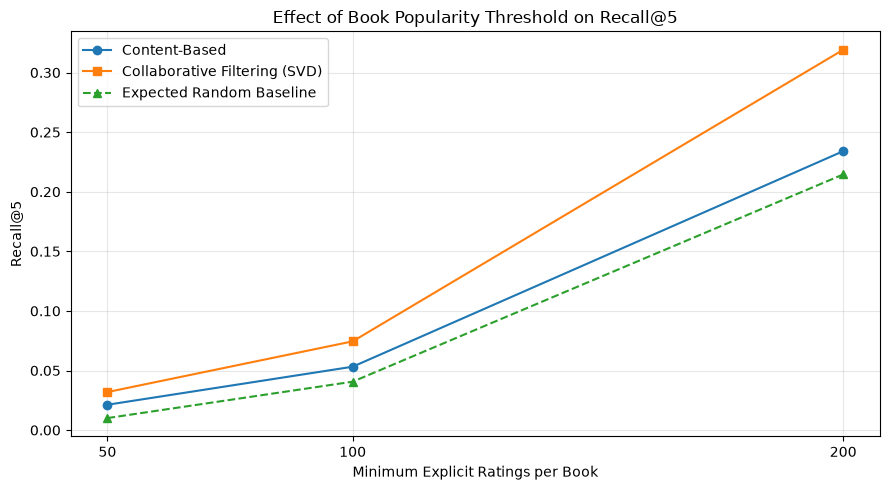

In [208]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))

plt.plot(
    corrected_content_results_df["Threshold"],
    corrected_content_results_df["Recall@5"],
    marker="o",
    label="Content-Based"
)

plt.plot(
    corrected_svd_results_df["Threshold"],
    corrected_svd_results_df["Recall@5"],
    marker="s",
    label="Collaborative Filtering (SVD)"
)

plt.plot(
    corrected_random_df["Threshold"],
    corrected_random_df["Expected Random Recall@5"],
    marker="^",
    linestyle="--",
    label="Expected Random Baseline"
)

plt.xlabel("Minimum Explicit Ratings per Book")
plt.ylabel("Recall@5")
plt.title("Effect of Book Popularity Threshold on Recall@5")
plt.xticks([50, 100, 200])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Popularity-Threshold Experiment Results

This experiment examined how book-popularity thresholds affect the performance of content-based filtering and SVD collaborative filtering. Three thresholds were tested: 50, 100, and 200 explicit ratings per book.

To ensure a fair comparison, both algorithms were evaluated using the same 94 users, with one relevant book (rating ≥ 7) held out per user. Book popularity was calculated using training ratings only to prevent held-out test ratings from influencing catalog eligibility. Both algorithms generated top-5 recommendations, evaluated using Precision@5 and Recall@5.

| Popularity Threshold | Content-Based Recall@5 | SVD Recall@5 | Expected Random Recall@5 |
|---|---|---|---|
| 50 | 0.0213 | 0.0319 | ≈ 0.01 |
| 100 | 0.0532 | 0.0745 | ≈ 0.04 |
| 200 | 0.2340 | 0.3191 | ≈ 0.21 |

SVD achieved higher Recall@5 than content-based filtering at all three thresholds. Both algorithms showed increasing recall as the popularity threshold increased.

However, increasing the threshold also reduced the number of eligible books. The expected random baseline increased as well, indicating that the smaller candidate catalogs contributed to the higher recall values.

These findings suggest that book-popularity filtering significantly affects recommendation performance and must be considered when comparing recommendation algorithms. The results are based on a single held-out evaluation split, so further experiments are needed to assess their stability.

### Interpretation Across Experiments

The sparsity and popularity experiments investigate different factors affecting recommendation performance. The sparsity experiment varied the number of available user ratings, while the popularity experiment varied the minimum number of ratings required for books to enter the recommendation catalog.

The sparsity experiment favored content-based filtering under its tested conditions, whereas the corrected popularity experiment favored SVD. This difference suggests that relative algorithm performance depends on the evaluation conditions rather than one method consistently outperforming the other.

In [203]:
def get_top_n_recommendations(user_id, model, df_clean, n=5):
    all_books = df_clean['ISBN'].unique()
    rated_books = df_clean[df_clean['User-ID'] == user_id]['ISBN'].unique()
    unseen_books = [book for book in all_books if book not in rated_books]

    predictions = [model.predict(user_id, book) for book in unseen_books]
    predictions.sort(key=lambda x: x.est, reverse=True)

    top_isbns = [pred.iid for pred in predictions[:n]]

    # Get unique book info (in case of duplicates)
    book_info = df_clean[['ISBN', 'Book-Title']].drop_duplicates()
    top_titles = book_info[book_info['ISBN'].isin(top_isbns)]

    return top_titles

**SVD Output and Initial Results:**

- **RMSE:** 1.6460  

  The Root Mean Squared Error (RMSE) measures the difference between the predicted and actual ratings in the test set. A lower RMSE indicates better rating-prediction performance.

- **Top-N Evaluation:**  

  The initial top-N evaluation requires revision. The current evaluation removes books that appear in the user's full rating history, including held-out test items, from the recommendation candidates. This can prevent the model from recommending the items it is being evaluated against.

  The top-N evaluation will therefore be updated before reporting Hit Rate@5, Precision@5, and Recall@5 results.

> At this stage, RMSE = 1.6460 is the valid initial SVD evaluation result. The top-N recommendation metrics will be reported after the evaluation methodology is corrected.

In [204]:
user_id = df['User-ID'].sample(1).iloc[0]
recommended_books = get_top_n_recommendations(user_id, model, df_clean, n=5)

print(f"Top recommended books for user {user_id}:\n")
print(recommended_books)


Top recommended books for user 187966:

              ISBN                                         Book-Title
3956    0446310786                              To Kill a Mockingbird
21614   0142001740                            The Secret Life of Bees
41270   0385504209                                  The Da Vinci Code
95596   059035342X  Harry Potter and the Sorcerer's Stone (Harry P...
182669  043935806X  Harry Potter and the Order of the Phoenix (Boo...


### Preliminary SVD Ranking Evaluation

To evaluate the collaborative filtering model as a ranking system, I defined a relevant book as a held-out test book with a rating of 7 or higher. Books seen by each user during training were excluded from the recommendation candidates.

For this preliminary evaluation, I tested the first 50 users and sampled 200 unseen candidate books per user to reduce computation time. Relevant held-out books were always included in the candidate set.

**Initial Results**
- Precision@5: 0.1787
- Recall@5: 0.0796
- Eligible users evaluated: 47

These results are preliminary and are not directly comparable with the content-based results from the earlier evaluation because the models used different candidate-set configurations. Later controlled experiments use consistent evaluation conditions to compare both algorithms.

**Top-N Recommendations Example:**

The SVD model generates a ranked list of five recommended books for a sample user based on predicted ratings for books the user has not already rated. The example output above demonstrates the recommendations produced during the current run.

Because the sample user is selected randomly, the user and recommended books may change when the notebook is rerun. A fixed sample user will be used in the final experiment to make the results reproducible.

#### Comparison of Methods

Both content-based filtering and SVD collaborative filtering have been implemented and evaluated using the Book-Crossing dataset. In addition to the initial model evaluations, two controlled experiments were conducted to investigate how user-rating sparsity and book-popularity thresholds affect recommendation performance.

**Content-Based Filtering**

- **Approach:** Uses book title, author, and publisher metadata with TF-IDF and cosine similarity.
- **Initial Result:** Hit Rate@5 = 0.1096.
- **Strengths:** Produces relatively interpretable recommendations based on book metadata and can perform well when limited user-rating history is available.
- **Limitations:** Depends on the quality of book metadata and may not capture preferences beyond content similarity.

**SVD Collaborative Filtering**

- **Approach:** Uses explicit user-book ratings and matrix factorization to learn patterns in user preferences.
- **Initial Result:** RMSE = 1.6460.
- **Strengths:** Can learn patterns from user-item interactions that are not directly represented in book metadata.
- **Limitations:** Requires sufficient interaction data and faces cold-start challenges for new users and books.

##### Experimental Comparison

**Experiment 1: User-Rating Sparsity**

The sparsity experiment evaluated both algorithms using 1, 2, 3, and 4 available training ratings per user. Results were averaged across five random seeds and 461 evaluation users.

Content-based filtering achieved higher mean Recall@5 at all four sparsity levels, ranging from 0.1080 to 0.1210. SVD achieved mean Recall@5 values ranging from 0.0820 to 0.0959.

These results suggest that content-based filtering performed better under the sparse-user-history conditions tested.

**Experiment 2: Book-Popularity Thresholds**

The popularity experiment compared both algorithms at minimum thresholds of 50, 100, and 200 explicit ratings per book, using the same 94 evaluation users.

| Popularity Threshold | Content-Based Recall@5 | SVD Recall@5 |
|---|---|---|
| 50 | 0.0213 | 0.0319 |
| 100 | 0.0532 | 0.0745 |
| 200 | 0.2340 | 0.3191 |

SVD achieved higher Recall@5 at every threshold. Although both algorithms showed increasing recall at higher thresholds, the number of eligible books decreased substantially. Therefore, some improvement can be attributed to smaller recommendation candidate catalogs.

## Experiment 3: Multi-Book Content-Based User Profiles

In [209]:
print("Training data:", controlled_train_df.shape)
print("Testing data:", controlled_test_df.shape)
print("Books:", controlled_books.shape)
print("Similarity matrix:", controlled_cos_sim.shape)

Training data: (2959, 9)
Testing data: (461, 9)
Books: (81, 10)
Similarity matrix: (81, 81)


In [210]:
def recommend_multi_book(user_id, top_n=5):
    # Get the user's training history
    user_history = controlled_train_df[
        controlled_train_df["User-ID"] == user_id
    ]

    # Select books the user liked (rating >= 7)
    liked_books = user_history[
        user_history["Book-Rating"] >= 7
    ]["ISBN"].tolist()

    # If there are no positively rated books, return no recommendations
    if not liked_books:
        return []

    # Find their positions in the similarity matrix
    liked_indices = [
        controlled_book_indices[isbn]
        for isbn in liked_books
        if isbn in controlled_book_indices
    ]

    if not liked_indices:
        return []

    # Average similarity scores across all liked books
    average_similarity = controlled_cos_sim[liked_indices].mean(axis=0)

    # Exclude books already rated by the user
    seen_books = set(user_history["ISBN"])

    candidate_books = [
        isbn for isbn in common_books
        if isbn not in seen_books
        and isbn in controlled_book_indices
    ]

    # Rank candidates by their average similarity
    scored_books = [
        (isbn, average_similarity[controlled_book_indices[isbn]])
        for isbn in candidate_books
    ]

    scored_books.sort(key=lambda x: x[1], reverse=True)

    return [isbn for isbn, score in scored_books[:top_n]]

print("Multi-book recommendation function created successfully!")

Multi-book recommendation function created successfully!


In [212]:
multi_precision_scores = []
multi_recall_scores = []

for uid in controlled_test_df["User-ID"].unique():

    # One relevant book held out for each user
    relevant_book = controlled_test_df[
        controlled_test_df["User-ID"] == uid
    ]["ISBN"].iloc[0]

    # Generate recommendations using multiple liked books
    recommendations = recommend_multi_book(uid, top_n=5)

    hit = relevant_book in recommendations

    multi_precision_scores.append(int(hit) / 5)
    multi_recall_scores.append(int(hit))

multi_precision = np.mean(multi_precision_scores)
multi_recall = np.mean(multi_recall_scores)

print(f"Multi-Book Precision@5: {multi_precision:.4f}")
print(f"Multi-Book Recall@5: {multi_recall:.4f}")
print(f"Users evaluated: {len(multi_recall_scores)}")
users_without_liked_books = sum(
    controlled_train_df[
        (controlled_train_df["User-ID"] == uid) &
        (controlled_train_df["Book-Rating"] >= 7)
    ].empty
    for uid in controlled_test_df["User-ID"].unique()
)

print("Users with no liked training books:", users_without_liked_books)

Multi-Book Precision@5: 0.0304
Multi-Book Recall@5: 0.1518
Users evaluated: 461
Users with no liked training books: 6


In [213]:
print("Single-Book Precision@5:", round(controlled_content_precision, 4))
print("Single-Book Recall@5:", round(controlled_content_recall, 4))

print("Multi-Book Precision@5:", round(multi_precision, 4))
print("Multi-Book Recall@5:", round(multi_recall, 4))

Single-Book Precision@5: 0.0221
Single-Book Recall@5: 0.1106
Multi-Book Precision@5: 0.0304
Multi-Book Recall@5: 0.1518


In [214]:
single_hits = np.array(content_recall_scores, dtype=int)
multi_hits = np.array(multi_recall_scores, dtype=int)

print("Users evaluated:", len(single_hits))
print("Both methods succeeded:", np.sum((single_hits == 1) & (multi_hits == 1)))
print("Only single-book succeeded:", np.sum((single_hits == 1) & (multi_hits == 0)))
print("Only multi-book succeeded:", np.sum((single_hits == 0) & (multi_hits == 1)))
print("Neither method succeeded:", np.sum((single_hits == 0) & (multi_hits == 0)))

Users evaluated: 461
Both methods succeeded: 26
Only single-book succeeded: 25
Only multi-book succeeded: 44
Neither method succeeded: 366


In [215]:
from scipy.stats import binomtest

single_only = 25
multi_only = 44

result = binomtest(
    k=multi_only,
    n=single_only + multi_only,
    p=0.5,
    alternative="two-sided"
)

print(f"McNemar exact test p-value: {result.pvalue:.4f}")

McNemar exact test p-value: 0.0295


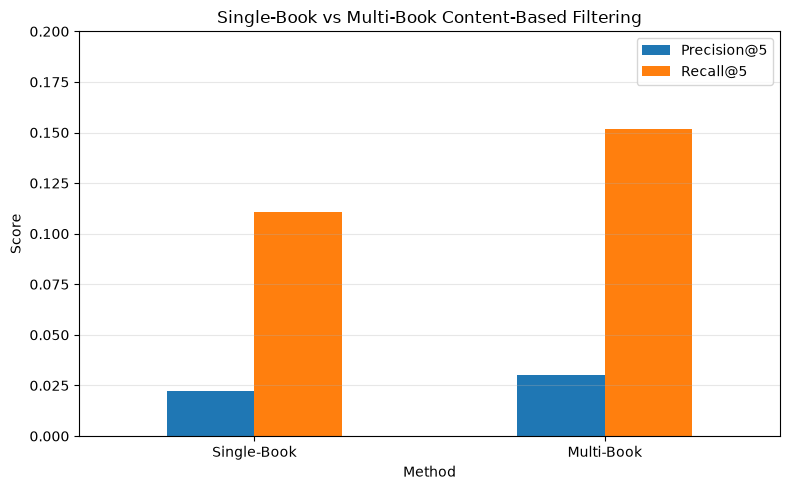

In [216]:
comparison = pd.DataFrame({
    "Method": ["Single-Book", "Multi-Book"],
    "Precision@5": [controlled_content_precision, multi_precision],
    "Recall@5": [controlled_content_recall, multi_recall]
})

ax = comparison.set_index("Method").plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Single-Book vs Multi-Book Content-Based Filtering")
plt.ylabel("Score")
plt.ylim(0, 0.20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [217]:
VALIDATION_SEEDS = [42, 7, 21, 100, 123]

validation_df = controlled_eval_df.copy()

print("Random seeds:", VALIDATION_SEEDS)
print("Eligible users:", validation_df["User-ID"].nunique())
print("Interactions:", len(validation_df))
print("Books:", validation_df["ISBN"].nunique())

Random seeds: [42, 7, 21, 100, 123]
Eligible users: 465
Interactions: 3453
Books: 81


In [218]:
def create_validation_split(data, seed):
    rng = np.random.default_rng(seed)

    train_parts = []
    test_parts = []

    for uid, user_data in data.groupby("User-ID"):

        relevant_items = user_data[
            user_data["Book-Rating"] >= 7
        ]

        if relevant_items.empty:
            continue

        # Hold out one positively rated book
        test_index = rng.choice(relevant_items.index)

        test_parts.append(user_data.loc[[test_index]])
        train_parts.append(user_data.drop(index=test_index))

    train = pd.concat(train_parts).reset_index(drop=True)
    test = pd.concat(test_parts).reset_index(drop=True)

    return train, test


# Test the function using seed 42
validation_train, validation_test = create_validation_split(
    validation_df, seed=42
)

print("Training interactions:", len(validation_train))
print("Testing interactions:", len(validation_test))
print("Users evaluated:", validation_test["User-ID"].nunique())
print("Train/test overlap:", len(
    set(zip(validation_train["User-ID"], validation_train["ISBN"])) &
    set(zip(validation_test["User-ID"], validation_test["ISBN"]))
))

Training interactions: 2959
Testing interactions: 461
Users evaluated: 461
Train/test overlap: 0


In [219]:
def evaluate_content_methods(train, test, catalog, k=5):

    # Build the content-based model using training data
    books = train.drop_duplicates("ISBN").reset_index(drop=True).copy()

    books["metadata"] = (
        books["Book-Title"].fillna("").astype(str) + " " +
        books["Book-Author"].fillna("").astype(str) + " " +
        books["Publisher"].fillna("").astype(str)
    )

    vectorizer = TfidfVectorizer(
        stop_words="english",
        max_features=TFIDF_MAX_FEATURES
    )

    matrix = vectorizer.fit_transform(books["metadata"])
    similarity = cosine_similarity(matrix)

    book_index = {
        isbn: i for i, isbn in enumerate(books["ISBN"])
    }

    single_hits = []
    multi_hits = []

    for uid, user_history in train.groupby("User-ID"):

        test_rows = test[test["User-ID"] == uid]

        if test_rows.empty:
            continue

        relevant_book = test_rows["ISBN"].iloc[0]
        seen = set(user_history["ISBN"])

        candidates = [
            isbn for isbn in catalog
            if isbn not in seen and isbn in book_index
        ]

        # Original method: highest-rated book
        top_book = user_history.sort_values(
            "Book-Rating", ascending=False
        )["ISBN"].iloc[0]

        single_scores = [
            (isbn, similarity[book_index[top_book], book_index[isbn]])
            for isbn in candidates
        ]

        single_scores.sort(key=lambda x: x[1], reverse=True)
        single_top = [isbn for isbn, _ in single_scores[:k]]

        # Improved method: average similarity across liked books
        liked = user_history[
            user_history["Book-Rating"] >= 7
        ]["ISBN"].tolist()

        if liked:
            liked_indices = [book_index[isbn] for isbn in liked]
            avg_similarity = similarity[liked_indices].mean(axis=0)

            multi_scores = [
                (isbn, avg_similarity[book_index[isbn]])
                for isbn in candidates
            ]

            multi_scores.sort(key=lambda x: x[1], reverse=True)
            multi_top = [isbn for isbn, _ in multi_scores[:k]]
        else:
            multi_top = []

        single_hits.append(int(relevant_book in single_top))
        multi_hits.append(int(relevant_book in multi_top))

    return {
        "Single Precision@5": np.mean(single_hits) / k,
        "Single Recall@5": np.mean(single_hits),
        "Multi Precision@5": np.mean(multi_hits) / k,
        "Multi Recall@5": np.mean(multi_hits),
        "Users": len(single_hits)
    }


print("Validation evaluation function created successfully!")

Validation evaluation function created successfully!


In [220]:
validation_results = []

for seed in VALIDATION_SEEDS:
    train, test = create_validation_split(validation_df, seed)

    results = evaluate_content_methods(
        train=train,
        test=test,
        catalog=common_books,
        k=5
    )

    results["Seed"] = seed
    validation_results.append(results)

    print(
        f"Seed {seed}: "
        f"Single Recall@5 = {results['Single Recall@5']:.4f}, "
        f"Multi Recall@5 = {results['Multi Recall@5']:.4f}"
    )

validation_results_df = pd.DataFrame(validation_results)

display(validation_results_df)

Seed 42: Single Recall@5 = 0.1106, Multi Recall@5 = 0.1518
Seed 7: Single Recall@5 = 0.1432, Multi Recall@5 = 0.1584
Seed 21: Single Recall@5 = 0.1085, Multi Recall@5 = 0.1302
Seed 100: Single Recall@5 = 0.1215, Multi Recall@5 = 0.1562
Seed 123: Single Recall@5 = 0.1345, Multi Recall@5 = 0.1475


,Single Precision@5,Single Recall@5,Multi Precision@5,Multi Recall@5,Users,Seed
0,0.02,0.11,0.03,0.15,461,42
1,0.03,0.14,0.03,0.16,461,7
2,0.02,0.11,0.03,0.13,461,21
3,0.02,0.12,0.03,0.16,461,100
4,0.03,0.13,0.03,0.15,461,123


In [221]:
metrics = [
    "Single Precision@5",
    "Single Recall@5",
    "Multi Precision@5",
    "Multi Recall@5"
]

summary = validation_results_df[metrics].agg(["mean", "std"])

print("Five-seed validation summary:")
display(summary.round(4))

Five-seed validation summary:


,Single Precision@5,Single Recall@5,Multi Precision@5,Multi Recall@5
mean,0.02,0.12,0.03,0.15
std,0.00,0.01,0.00,0.01


In [222]:
print(summary.to_string(float_format=lambda x: f"{x:.4f}"))

      Single Precision@5  Single Recall@5  Multi Precision@5  Multi Recall@5
mean              0.0247           0.1236             0.0298          0.1488
std               0.0030           0.0150             0.0022          0.0112


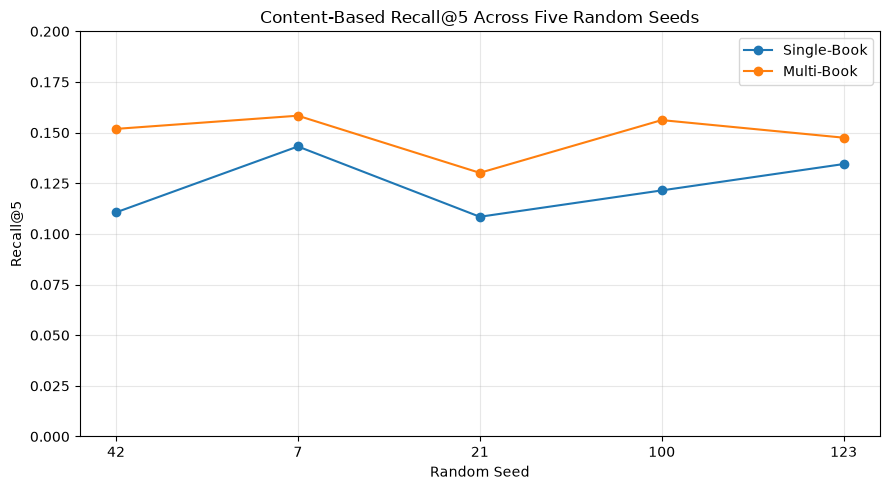

In [223]:
plt.figure(figsize=(9, 5))

plt.plot(
    validation_results_df["Seed"].astype(str),
    validation_results_df["Single Recall@5"],
    marker="o",
    label="Single-Book"
)

plt.plot(
    validation_results_df["Seed"].astype(str),
    validation_results_df["Multi Recall@5"],
    marker="o",
    label="Multi-Book"
)

plt.title("Content-Based Recall@5 Across Five Random Seeds")
plt.xlabel("Random Seed")
plt.ylabel("Recall@5")
plt.ylim(0, 0.20)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##### Overall Findings and Limitations

The two experiments demonstrate that recommendation performance depends on the evaluation conditions. Content-based filtering performed better in the sparsity experiment, while SVD performed better in the popularity-threshold experiment.

The experiments used different evaluation setups, so their absolute Recall@5 values should not be directly compared across experiments.

The popularity experiment used one held-out split, and additional random seeds would help assess the stability of its findings.



##### Future Work

Future work will focus on testing additional datasets, examining cold-start behavior, and evaluating whether a hybrid approach combining content-based and collaborative filtering can improve recommendation performance.